# 3.2 - Part B: Clustering Bike-Sharing Stations

**Team Members**: *Zacharie Sulmont, Zakarya BOUMESSAOUD, Jayesh SWAMI, Nourane KAHLFALLI, Chi Bach PHAM and Bérénice CARDOSO--FAUCHER*

### Step 1: Setup

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import prince
import rasterio
from pyproj import Transformer
from scipy.stats import chi2_contingency
from sklearn.cluster import AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

In [2]:
stations = pd.read_csv("./data/stations.csv", sep=",")
station_status = pd.read_csv("./data/stations_status.csv", sep=",")

### Step 2: Column overview: `stations` and `station_status`

In [3]:
def column_overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "n_unique": df.nunique(),
        "example": df.iloc[0],
    })

for name, df in {"stations": stations, "station_status": station_status}.items():
    print(f"\n{name} - shape: {df.shape}")
    display(column_overview(df))


stations - shape: (2932, 11)


,dtype,non_null,nulls,n_unique,example
id,int64,2932,0,2932,142186362
city_id,int64,2932,0,185,135
name,str,2932,0,2855,BIKE 500100
app_number,int64,2932,0,2914,0
terminal_type,str,2345,587,10,NaN
place_type,int64,2932,0,16,12
bike_racks,int64,2932,0,33,0
special_racks,int64,2932,0,11,0
rack_locks,float64,0,2932,0,NaN
lon,float64,2932,0,2912,7.821669



station_status - shape: (2925967, 8)


,dtype,non_null,nulls,n_unique,example
station_id,int64,2925967,0,2899,101896428
time,float64,2925967,0,392858,1661530441.0
bikes,int64,2925967,0,185,2
booked_bikes,int64,2925967,0,40,0
bikes_available_to_rent,int64,2925967,0,185,2
free_racks,int64,2925967,0,68,0
free_special_racks,int64,2925967,0,38,0
maintenance,bool,2925967,0,2,False


### Step 3: Drop `rack_locks` from `stations`

The column is redundant (all 2,932 values are null).

In [4]:
assert stations["rack_locks"].isna().all()

stations = stations.drop(columns=["rack_locks"])
print(stations.shape)
print(list(stations.columns))

(2932, 10)
['id', 'city_id', 'name', 'app_number', 'terminal_type', 'place_type', 'bike_racks', 'special_racks', 'lon', 'lat']


### Step 4: Stations with and without `station_status` data

In [5]:
station_ids = set(stations["id"])
status_ids = set(station_status["station_id"])

with_status = station_ids & status_ids
without_status = station_ids - status_ids
status_not_in_stations = status_ids - station_ids

print("Stations total:", len(station_ids))
print(f"With status data: {len(with_status)} ({len(with_status) / len(station_ids):.2%})")
print("Without status data:", len(without_status))
print("Status station IDs missing from stations:", len(status_not_in_stations))

stations_without_status = stations[stations["id"].isin(without_status)]
stations_without_status

Stations total: 2932
With status data: 2899 (98.87%)
Without status data: 33
Status station IDs missing from stations: 0


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,7.821669,51.677449
11,258292,176,Hangar 10 am Flugplatz 5618,5618,stele,6,6,0,14.146521,53.876952
13,140911390,833,TMB Test station,34980,stele,14,10,0,2.143654,41.346571
28,11268759,557,Święta Jadwiga,3787,7inch,0,15,0,18.946631,50.292195
54,115413819,64,Ma. Enzersdorf / Gabrium,1,NaN,0,0,0,16.299178,48.094352
71,405832,302,Gnien Pembroke,6866,sign,0,8,0,14.488521,35.929510
92,216612,176,Pension Delia Will Ahlbeck 5615,5615,sign,6,6,0,14.179120,53.941858
93,271479,176,Ferienpark Benz 5616,5616,stele,6,6,0,14.074235,53.939402
102,405841,302,Mater Dei Hospital,6871,sign,0,12,0,14.475673,35.901561
194,153092,775,Hotel Ostseeländer Züssow 57141,57141,NaN,7,6,0,13.553034,53.979870


### Step 5: Drop stations with no `station_status` data

In [6]:
n_before = len(stations)
stations = stations[stations["id"].isin(station_status["station_id"])]

print("Rows before:", n_before)
print("Rows after:", len(stations))
print("Dropped:", n_before - len(stations))

Rows before: 2932
Rows after: 2899
Dropped: 33


### Step 6: Load `cities` and summarise it

In [7]:
cities = pd.read_csv("./data/cities.csv", sep=",")

print(cities.shape)
cities.info()
cities.describe(include="all").T

(267, 7)
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 12.9 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 7: Drop cities with no stations

In [8]:
n_before = len(cities)
cities = cities[cities["id"].isin(stations["city_id"])]

print("Rows before:", n_before)
print("Rows after:", len(cities))
print("Dropped:", n_before - len(cities))

Rows before: 267
Rows after: 185
Dropped: 82


### Step 8: Local time columns for `station_status`

In [9]:
# station id -> timezone of its city
station_tz = stations[["id", "city_id"]].merge(
    cities[["id", "timezone"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["timezone"]
station_status["timezone"] = station_status["station_id"].map(station_tz)
print("Rows without a timezone:", station_status["timezone"].isna().sum())

# Unix seconds (UTC) -> local wall-clock time, converted one timezone at a time
utc_time = pd.to_datetime(station_status["time"], unit="s", utc=True)
local_time = pd.Series(pd.NaT, index=station_status.index, dtype="datetime64[ns]")
for tz, idx in station_status.groupby("timezone").groups.items():
    local_time.loc[idx] = utc_time.loc[idx].dt.tz_convert(tz).dt.tz_localize(None)
station_status["local_time"] = local_time

station_status["year"] = station_status["local_time"].dt.year
station_status["month"] = station_status["local_time"].dt.month
station_status["day"] = station_status["local_time"].dt.day
station_status["hour"] = station_status["local_time"].dt.hour            # 0-23
station_status["minute"] = station_status["local_time"].dt.minute
station_status["weekday"] = station_status["local_time"].dt.weekday      # 0 = Monday ... 6 = Sunday
station_status["weekday_name"] = station_status["local_time"].dt.day_name()

station_status[["station_id", "time", "timezone", "local_time", "year", "month",
                "day", "hour", "minute", "weekday", "weekday_name"]].head()

Rows without a timezone: 0


,station_id,time,timezone,local_time,year,month,day,hour,minute,weekday,weekday_name
0,101896428,1.661530e+09,Europe/Berlin,2022-08-26 18:14:01,2022,8,26,18,14,4,Friday
1,54643,1.661531e+09,Europe/Berlin,2022-08-26 18:15:01,2022,8,26,18,15,4,Friday
2,6201611,1.661531e+09,Europe/Brussels,2022-08-26 18:15:01,2022,8,26,18,15,4,Friday
3,294346,1.661531e+09,Europe/Riga,2022-08-26 19:15:01,2022,8,26,19,15,4,Friday
4,781866,1.661531e+09,Europe/Riga,2022-08-26 19:15:01,2022,8,26,19,15,4,Friday


### Step 9: `is_weekend` column

In [10]:
station_status["is_weekend"] = station_status["weekday"] >= 5

station_status["is_weekend"].value_counts()

is_weekend
False    2225416
True      700551
Name: count, dtype: int64

### Step 10: List of cities

In [11]:
with pd.option_context("display.max_rows", None):
    display(cities.sort_values("name").reset_index(drop=True))

,id,name,lat,lon,timezone,country,return_to_official_only
0,414,Amstetten,48.12180,14.877400,Europe/Berlin,AT,False
1,689,Bad Oeynhausen,52.20510,8.800740,Europe/Berlin,DE,True
2,621,Baden-Baden,48.73650,8.304820,Europe/Berlin,DE,False
3,833,Barcelona,41.40950,2.171770,Europe/Berlin,ES,True
4,332,Bensheim,49.68030,8.618900,Europe/Berlin,DE,True
5,676,Bergisches e-Bike,51.01920,7.180250,Europe/Berlin,DE,True
6,131,Bottrop,51.52630,6.946110,Europe/Berlin,DE,False
7,627,Bruchsal,49.12600,8.596800,Europe/Berlin,DE,False
8,392,Bürstadt,49.64610,8.449170,Europe/Berlin,DE,True
9,776,Chełm,51.13180,23.475500,Europe/Warsaw,PL,True


### Step 11: Time data of the 5 stations with the most `station_status` rows

The data seems to be polled at regular intervals (every minute) but cleaned so that only changes are kept.

In [12]:
n_show = 10   # rows shown per station

top5_ids = station_status["station_id"].value_counts().head(5)
print(top5_ids)

time_cols = ["station_id", "time", "utc_time", "local_time", "gap_s",
             "bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks", "maintenance"]

for station_id in top5_ids.index:
    rows = station_status[station_status["station_id"] == station_id].sort_values("time").copy()
    rows["utc_time"] = pd.to_datetime(rows["time"], unit="s")
    rows["gap_s"] = rows["time"].diff()          # seconds since the station's previous row
    name = stations.loc[stations["id"] == station_id, "name"].iloc[0]
    print(f"\nStation {station_id} ({name}): {len(rows):,} rows, first {n_show} shown")
    display(rows[time_cols].head(n_show))

station_id
286234       16643
142141673    15786
54635        15541
86926732     15323
142141545    13869
Name: count, dtype: int64

Station 286234 (Bahnhof Sursee): 16,643 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
85085,286234,1.661526e+09,2022-08-26 15:06:01,2022-08-26 17:06:01,NaN,9,0,9,0,0,False
85102,286234,1.661526e+09,2022-08-26 15:07:01,2022-08-26 17:07:01,60.0,10,0,10,0,0,False
85138,286234,1.661527e+09,2022-08-26 15:09:01,2022-08-26 17:09:01,120.0,11,0,11,0,0,False
85201,286234,1.661527e+09,2022-08-26 15:13:01,2022-08-26 17:13:01,240.0,12,0,12,0,0,False
85398,286234,1.661528e+09,2022-08-26 15:25:01,2022-08-26 17:25:01,720.0,13,0,13,0,0,False
85421,286234,1.661528e+09,2022-08-26 15:26:01,2022-08-26 17:26:01,60.0,14,0,14,0,0,False
85877,286234,1.661529e+09,2022-08-26 15:50:01,2022-08-26 17:50:01,1440.0,13,0,13,0,0,False
85985,286234,1.661529e+09,2022-08-26 15:56:01,2022-08-26 17:56:01,360.0,12,0,12,0,0,False
86041,286234,1.661530e+09,2022-08-26 15:59:01,2022-08-26 17:59:01,180.0,13,0,13,0,0,False
86076,286234,1.661530e+09,2022-08-26 16:01:01,2022-08-26 18:01:01,120.0,14,0,14,0,0,False



Station 142141673 (El Parador): 15,786 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
1233924,142141673,1.675100e+09,2023-01-30 17:34:01,2023-01-30 18:34:01,NaN,0,0,0,14,0,False
1233929,142141673,1.675100e+09,2023-01-30 17:35:01,2023-01-30 18:35:01,60.0,9,0,9,13,0,False
1234332,142141673,1.675109e+09,2023-01-30 19:55:01,2023-01-30 20:55:01,8400.0,10,0,10,12,0,False
1234562,142141673,1.675116e+09,2023-01-30 22:06:01,2023-01-30 23:06:01,7860.0,9,0,9,13,0,False
1234573,142141673,1.675117e+09,2023-01-30 22:17:01,2023-01-30 23:17:01,660.0,10,0,10,12,0,False
1234599,142141673,1.675119e+09,2023-01-30 22:44:01,2023-01-30 23:44:01,1620.0,9,0,9,13,0,False
1234635,142141673,1.675123e+09,2023-01-30 23:59:01,2023-01-31 00:59:01,4500.0,8,0,8,14,0,False
1236511,142141673,1.675167e+09,2023-01-31 12:05:01,2023-01-31 13:05:01,43560.0,9,0,9,13,0,False
1236721,142141673,1.675169e+09,2023-01-31 12:49:01,2023-01-31 13:49:01,2640.0,8,0,8,14,0,False
1236905,142141673,1.675172e+09,2023-01-31 13:27:01,2023-01-31 14:27:01,2280.0,9,0,9,13,0,False



Station 54635 (Wr. Neustadt / Hauptbahnhof): 15,541 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
84864,54635,1.661526e+09,2022-08-26 14:54:01,2022-08-26 16:54:01,NaN,15,0,15,0,0,False
84898,54635,1.661526e+09,2022-08-26 14:56:01,2022-08-26 16:56:01,120.0,14,0,14,0,0,False
85155,54635,1.661527e+09,2022-08-26 15:10:01,2022-08-26 17:10:01,840.0,15,0,15,0,0,False
86211,54635,1.661530e+09,2022-08-26 16:07:01,2022-08-26 18:07:01,3420.0,17,0,17,0,0,False
773,54635,1.661533e+09,2022-08-26 16:54:01,2022-08-26 18:54:01,2820.0,15,0,15,0,0,False
793,54635,1.661533e+09,2022-08-26 16:55:01,2022-08-26 18:55:01,60.0,14,0,14,0,0,False
820,54635,1.661533e+09,2022-08-26 16:56:01,2022-08-26 18:56:01,60.0,13,0,13,0,0,False
2285,54635,1.661538e+09,2022-08-26 18:15:01,2022-08-26 20:15:01,4740.0,14,0,14,0,0,False
2553,54635,1.661539e+09,2022-08-26 18:29:01,2022-08-26 20:29:01,840.0,15,0,15,0,0,False
2658,54635,1.661539e+09,2022-08-26 18:36:01,2022-08-26 20:36:01,420.0,17,0,17,0,0,False



Station 86926732 (Tržnica Veruda): 15,323 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
4258,86926732,1.661547e+09,2022-08-26 20:51:01,2022-08-26 22:51:01,NaN,2,0,2,2,2,False
14400,86926732,1.661617e+09,2022-08-27 16:17:01,2022-08-27 18:17:01,69960.0,4,0,4,2,2,False
16139,86926732,1.661622e+09,2022-08-27 17:43:01,2022-08-27 19:43:01,5160.0,2,0,2,2,2,False
16834,86926732,1.661624e+09,2022-08-27 18:18:01,2022-08-27 20:18:01,2100.0,0,0,0,2,2,False
21599,86926732,1.661661e+09,2022-08-28 04:22:01,2022-08-28 06:22:01,36240.0,1,0,1,1,1,False
32038,86926732,1.661708e+09,2022-08-28 17:26:01,2022-08-28 19:26:01,47040.0,2,0,2,1,1,False
32054,86926732,1.661708e+09,2022-08-28 17:27:01,2022-08-28 19:27:01,60.0,3,0,3,1,1,False
32106,86926732,1.661708e+09,2022-08-28 17:29:01,2022-08-28 19:29:01,120.0,1,0,1,1,1,False
32364,86926732,1.661709e+09,2022-08-28 17:44:01,2022-08-28 19:44:01,900.0,1,0,1,2,2,False
32634,86926732,1.661710e+09,2022-08-28 18:04:01,2022-08-28 20:04:01,1200.0,0,0,0,2,2,False



Station 142141545 (TRAM Walden): 13,869 rows, first 10 shown


,station_id,time,utc_time,local_time,gap_s,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
1233784,142141545,1.675098e+09,2023-01-30 17:06:01,2023-01-30 18:06:01,NaN,9,0,9,13,0,False
1236088,142141545,1.675160e+09,2023-01-31 10:16:01,2023-01-31 11:16:01,61800.0,10,0,10,12,0,False
1236495,142141545,1.675166e+09,2023-01-31 12:01:01,2023-01-31 13:01:01,6300.0,9,0,9,13,0,False
1236498,142141545,1.675167e+09,2023-01-31 12:02:01,2023-01-31 13:02:01,60.0,8,0,8,14,0,False
1236502,142141545,1.675167e+09,2023-01-31 12:03:01,2023-01-31 13:03:01,60.0,9,0,9,13,0,False
1237004,142141545,1.675173e+09,2023-01-31 13:51:01,2023-01-31 14:51:01,6480.0,8,0,8,14,0,False
1237057,142141545,1.675174e+09,2023-01-31 14:04:01,2023-01-31 15:04:01,780.0,9,0,9,13,0,False
1237482,142141545,1.675179e+09,2023-01-31 15:23:01,2023-01-31 16:23:01,4740.0,10,0,10,12,0,False
1238647,142141545,1.675196e+09,2023-01-31 20:08:01,2023-01-31 21:08:01,17100.0,9,0,9,13,0,False
1238679,142141545,1.675196e+09,2023-01-31 20:17:01,2023-01-31 21:17:01,540.0,10,0,10,12,0,False


### Step 12: `station_status` record counts by hour, month and country

"usage" is measured as the number of `station_status` rows (chosen over drops in `bikes` and trip counts).

In [13]:
by_hour = station_status.groupby("hour").size().rename("records")
by_hour

hour
0      47642
1      35141
2      26526
3      22448
4      25389
5      41708
6      74399
7     134172
8     137891
9     124279
10    120963
11    138523
12    158849
13    178702
14    194190
15    209154
16    227343
17    225143
18    205148
19    175649
20    146310
21    117611
22     91946
23     66841
Name: records, dtype: int64

In [14]:
by_month = station_status.groupby("month").size().rename("records")
by_month

month
1     110438
2     138982
3     213703
4     308125
5     280834
6     491598
7     253738
8      85997
9     369992
10    363426
11    206644
12    102490
Name: records, dtype: int64

In [15]:
# station id -> country of its city
station_country = stations[["id", "city_id"]].merge(
    cities[["id", "country"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["country"]

by_country = station_status["station_id"].map(station_country).value_counts().rename("records")
by_country

station_id
PL    908603
DE    743405
ES    297611
GB    192759
AT    167921
HR    167720
CZ    164818
CH    148663
SI    101366
CY     17318
LV     13952
MT      1831
Name: records, dtype: int64

### Step 13: Bar charts of the Step 12 counts

The sudden drop in months 7–8 is only because of the data (these months are only partly covered), not a real dip in usage.

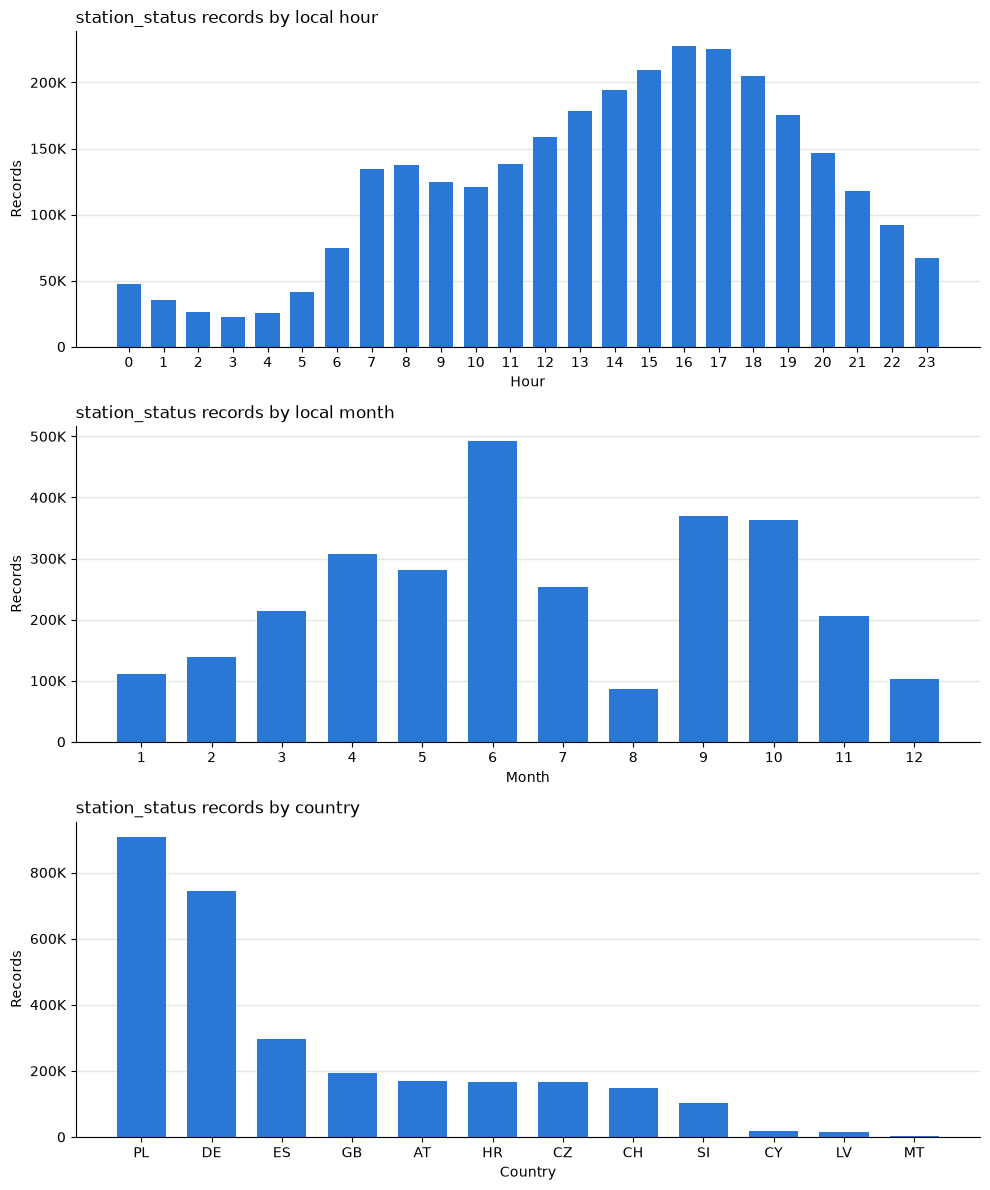

In [16]:
bar_color = "#2a78d6"
thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}K" if v else "0")

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
charts = [
    (by_hour, "station_status records by local hour", "Hour"),
    (by_month, "station_status records by local month", "Month"),
    (by_country, "station_status records by country", "Country"),
]
for ax, (series, title, xlabel) in zip(axes, charts):
    ax.bar(series.index.astype(str), series.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Records")
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

### Step 14: Hourly `station_status` record counts per month and per country

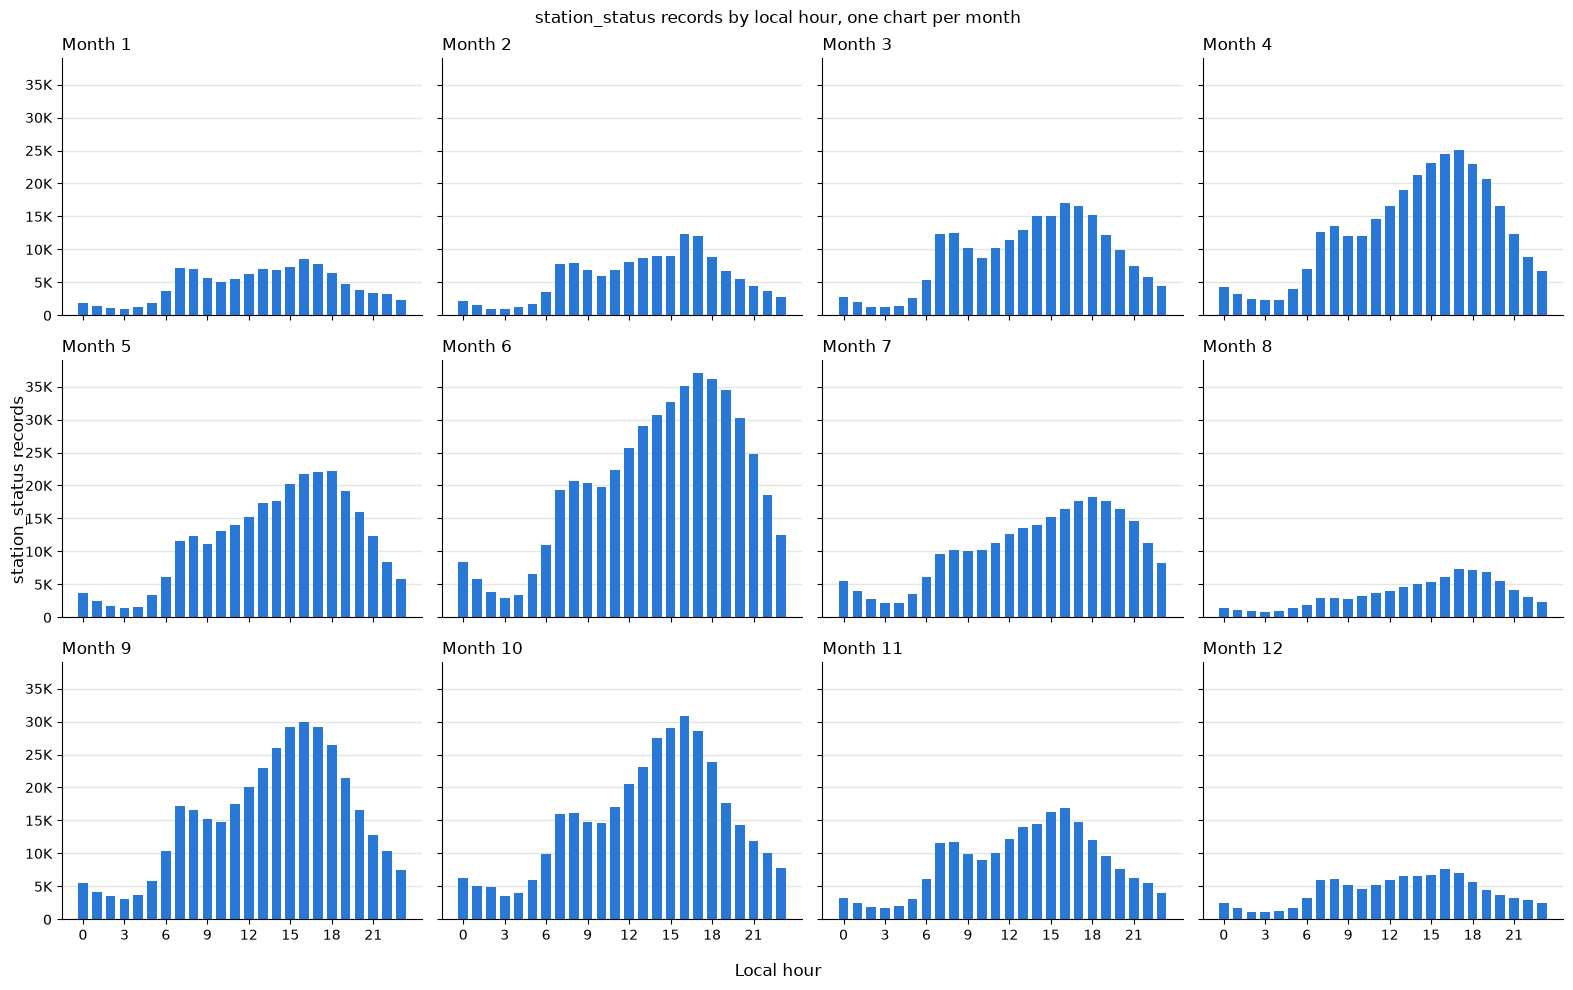

In [17]:
bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")

# rows: month, columns: local hour 0-23, values: number of station_status rows
hour_by_month = (
    station_status.groupby(["month", "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
for ax, (month, counts) in zip(axes.flat, hour_by_month.iterrows()):
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"Month {month}", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, one chart per month")
fig.tight_layout()
plt.show()

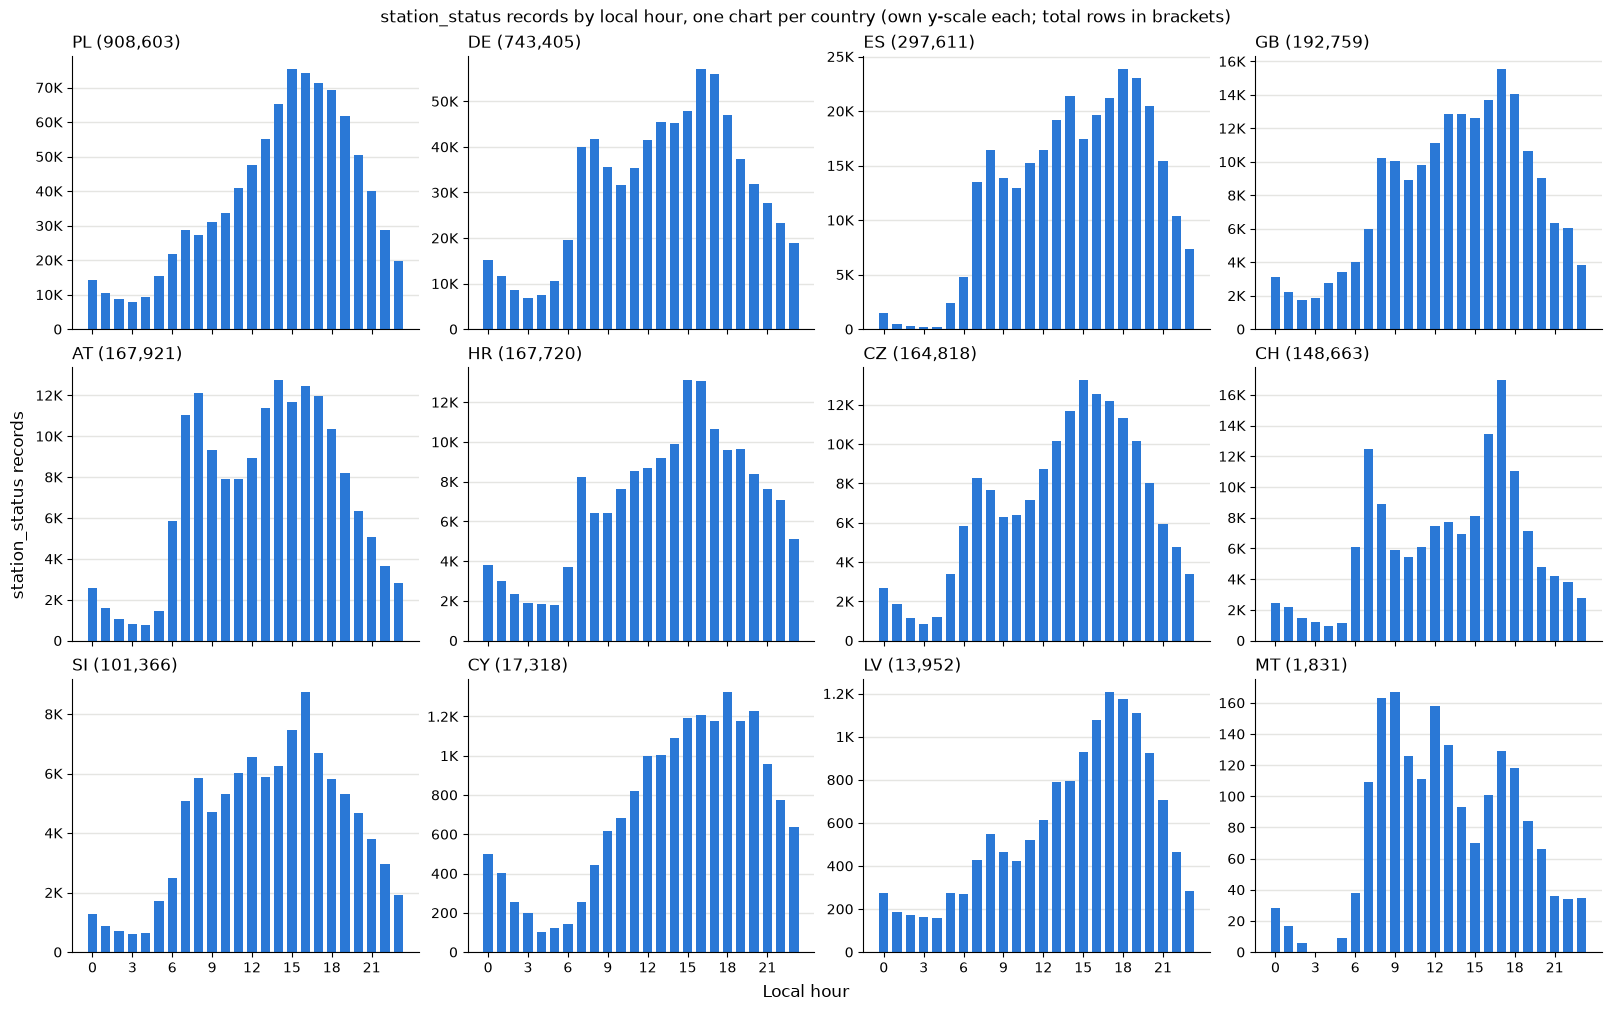

In [18]:
bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")

# station id -> country of its city
station_country = stations[["id", "city_id"]].merge(
    cities[["id", "country"]], left_on="city_id", right_on="id", suffixes=("", "_city")
).set_index("id")["country"]

# rows: country, columns: local hour 0-23, values: number of station_status rows
hour_by_country = (
    station_status.groupby([station_status["station_id"].map(station_country).rename("country"), "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)
# countries ordered from most to fewest rows
hour_by_country = hour_by_country.loc[hour_by_country.sum(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, layout="constrained")
for ax, (country, counts) in zip(axes.flat, hour_by_country.iterrows()):
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"{country} ({counts.sum():,})", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, one chart per country (own y-scale each; total rows in brackets)")
plt.show()

### Step 15: GHS-SMOD settlement class for each station

GHS-SMOD (R2023A, 1 km grid) chosen as the rural/urban source, linked to stations by location.

In [19]:
ghs_path = "./external_data/GHS_SMOD_E2030_GLOBE_R2023A_54009_1000_V2_0.tif"

# GHS-SMOD level 2 class codes and their level 1 group
# Source: GHSL_Data_Package_2023.pdf (in the downloaded GHS-SMOD folder)
#   p. 56: level 1 classes (3 Urban Centre, 2 Urban Cluster, 1 Rural)
#   pp. 56-57: level 2 classes 30, 23, 22, 21, 13, 12, 11 and 10 (Water)
smod_class = {
    30: "Urban centre",
    23: "Dense urban cluster",
    22: "Semi-dense urban cluster",
    21: "Suburban or peri-urban",
    13: "Rural cluster",
    12: "Low density rural",
    11: "Very low density rural",
    10: "Water",
}
smod_level1 = {30: "Urban centre", 23: "Urban cluster", 22: "Urban cluster", 21: "Urban cluster",
               13: "Rural", 12: "Rural", 11: "Rural", 10: "Water"}

with rasterio.open(ghs_path) as src:
    # station lon/lat (WGS84) -> grid coordinates (World Mollweide, metres)
    to_grid = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    x, y = to_grid.transform(stations["lon"].to_numpy(), stations["lat"].to_numpy())
    # value of the grid cell under each station
    codes = np.array([value[0] for value in src.sample(zip(x, y))])
    nodata = src.nodata

ghs_smod = pd.DataFrame({"station_id": stations["id"].to_numpy(), "x": x, "y": y, "smod_code": codes})
ghs_smod["smod_code"] = ghs_smod["smod_code"].astype("Int64")
ghs_smod.loc[ghs_smod["smod_code"] == nodata, "smod_code"] = pd.NA
ghs_smod["smod_class"] = ghs_smod["smod_code"].map(smod_class)
ghs_smod["smod_level1"] = ghs_smod["smod_code"].map(smod_level1)

print(ghs_smod.shape)
print(ghs_smod["smod_level1"].value_counts(dropna=False))
print(ghs_smod["smod_class"].value_counts(dropna=False))
ghs_smod.head()

(2899, 6)
smod_level1
Urban cluster    1437
Urban centre     1119
Rural             343
Name: count, dtype: int64
smod_class
Urban centre                1119
Dense urban cluster          784
Suburban or peri-urban       515
Low density rural            174
Semi-dense urban cluster     138
Rural cluster                125
Very low density rural        44
Name: count, dtype: int64


,station_id,x,y,smod_code,smod_class,smod_level1
0,940986,9.955353e+05,6.294868e+06,12,Low density rural,Rural
1,93646685,9.993904e+05,6.293101e+06,13,Rural cluster,Rural
2,111365509,-2.735846e+05,6.498408e+06,23,Dense urban cluster,Urban cluster
3,405835,1.273478e+06,4.326949e+06,30,Urban centre,Urban centre
4,8612883,1.280130e+06,4.321890e+06,30,Urban centre,Urban centre


### Step 16: Hourly and monthly `station_status` record counts per GHS-SMOD group

The different types of area (rural/urban) do not have any major difference in usage across hours of the day and months.

In [20]:
# settlement class of each status row, through station_id -> ghs_smod (Step 15)
station_smod = ghs_smod.set_index("station_id")
station_status["smod_class"] = station_status["station_id"].map(station_smod["smod_class"])
station_status["smod_level1"] = station_status["station_id"].map(station_smod["smod_level1"])
print("Rows without a class:", station_status["smod_class"].isna().sum())

# group order: most to least urban
smod_class_order = ["Urban centre", "Dense urban cluster", "Semi-dense urban cluster", "Suburban or peri-urban",
                    "Rural cluster", "Low density rural", "Very low density rural"]
smod_level1_order = ["Urban centre", "Urban cluster", "Rural"]

bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")


def plot_counts_per_group(group_col, group_order, time_col, time_values, xticks, n_cols, title):
    """One bar chart per group: number of station_status rows for each value of time_col.
    Each chart has its own y-axis scale; the title shows the group's total rows."""
    counts = (
        station_status.groupby([group_col, time_col]).size()
        .unstack(fill_value=0)
        .reindex(index=[g for g in group_order if g in station_status[group_col].unique()],
                 columns=time_values, fill_value=0)
    )
    n_rows = math.ceil(len(counts) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows),
                             sharex=True, squeeze=False, layout="constrained")
    for ax, (group, row) in zip(axes.flat, counts.iterrows()):
        ax.bar(row.index, row.values, color=bar_color, width=0.7, zorder=2)
        ax.set_title(f"{group} ({row.sum():,})", loc="left")
        ax.set_xticks(xticks)
        ax.tick_params(labelbottom=True)
        ax.yaxis.set_major_formatter(compact)
        ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes.flat[len(counts):]:
        ax.set_visible(False)
    fig.supxlabel(f"Local {time_col}")
    fig.supylabel("station_status records")
    fig.suptitle(title + " (own y-scale each; total rows in brackets)")
    plt.show()
    return counts

Rows without a class: 0


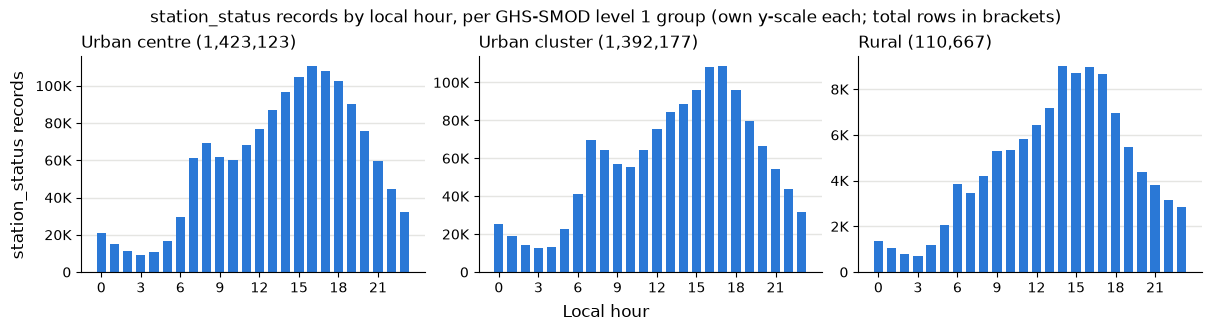

In [21]:
hour_by_level1 = plot_counts_per_group("smod_level1", smod_level1_order, "hour", range(24), range(0, 24, 3), 3,
                                       "station_status records by local hour, per GHS-SMOD level 1 group")

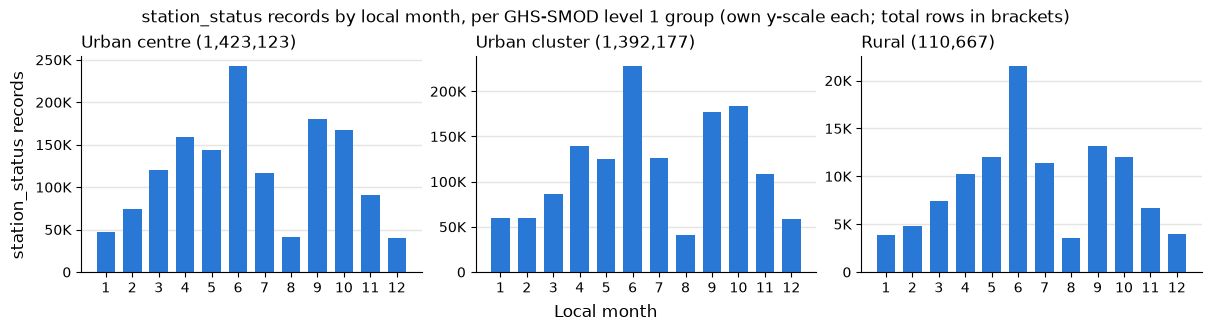

In [22]:
month_by_level1 = plot_counts_per_group("smod_level1", smod_level1_order, "month", range(1, 13), range(1, 13), 3,
                                        "station_status records by local month, per GHS-SMOD level 1 group")

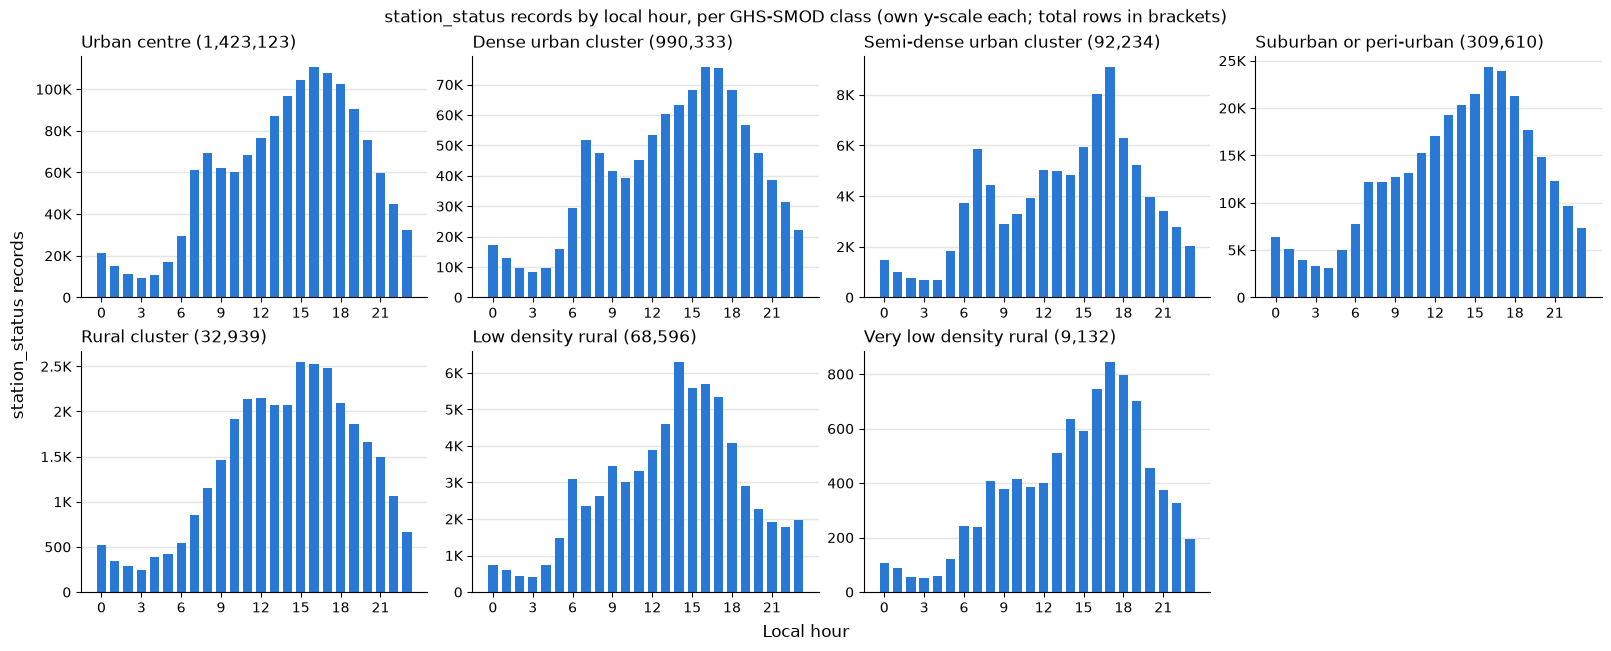

In [23]:
hour_by_class = plot_counts_per_group("smod_class", smod_class_order, "hour", range(24), range(0, 24, 3), 4,
                                      "station_status records by local hour, per GHS-SMOD class")

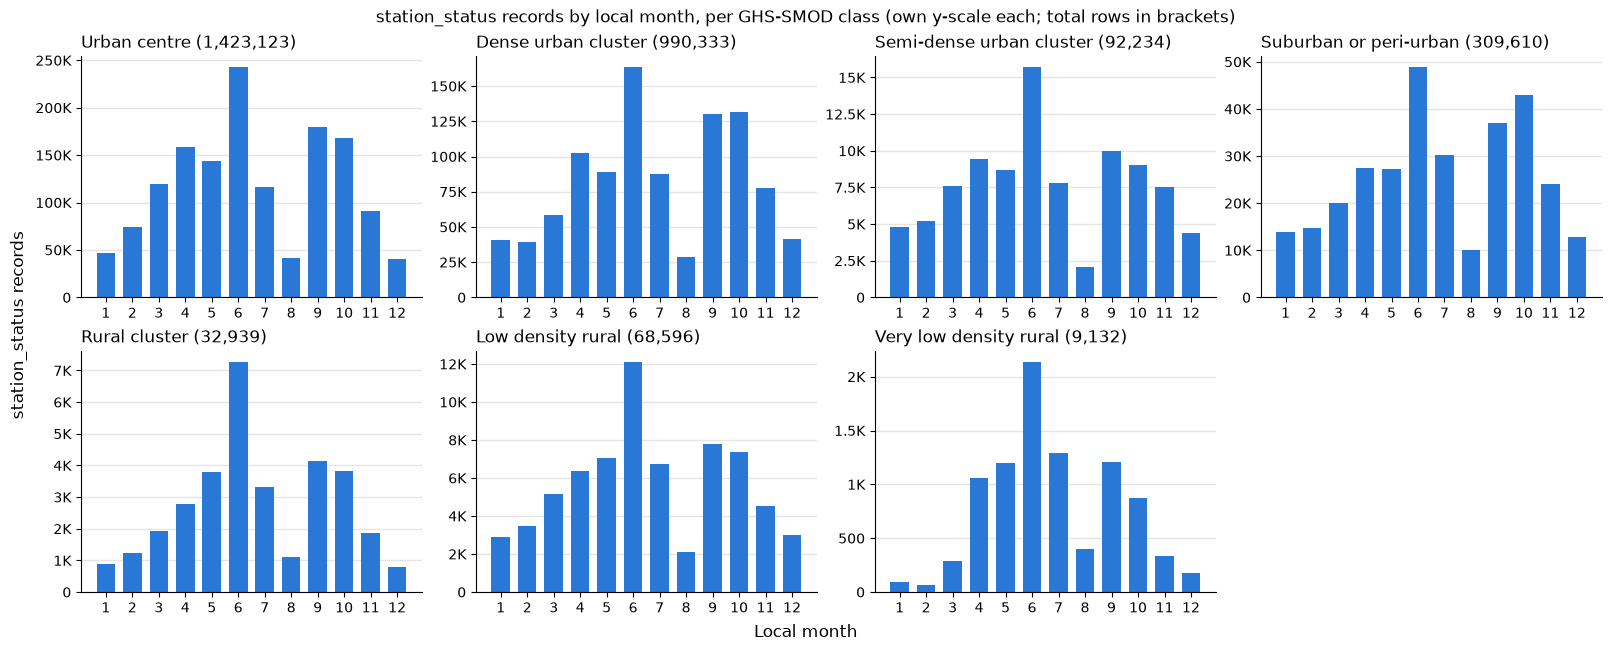

In [24]:
month_by_class = plot_counts_per_group("smod_class", smod_class_order, "month", range(1, 13), range(1, 13), 4,
                                       "station_status records by local month, per GHS-SMOD class")

### Step 17: Merge the GHS-SMOD classes into `stations`

In [25]:
n_before = len(stations)
stations = stations.merge(
    ghs_smod[["station_id", "smod_class", "smod_level1"]],
    left_on="id", right_on="station_id", how="left", validate="one_to_one",
).drop(columns=["station_id"])

print("Rows before:", n_before, "| after:", len(stations))
print("Stations without a class:", stations["smod_class"].isna().sum())
print(stations.shape)
stations.head()

Rows before: 2899 | after: 2899
Stations without a class: 0
(2899, 12)


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,lon,lat,smod_class,smod_level1
0,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,13.868973,54.090538,Low density rural,Rural
1,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,13.918970,54.073088,Rural cluster,Rural
2,111365509,243,Station Road,8494,smart_sign,0,20,0,-3.936120,56.119272,Dense urban cluster,Urban cluster
3,405835,302,Birkirkara Road,6868,sign,0,6,0,14.481456,35.906836,Urban centre,Urban centre
4,8612883,302,Wasteserv,6839,7inch,0,6,0,14.552025,35.862522,Urban centre,Urban centre


### Step 18: Hourly `station_status` record counts, weekday vs weekend

On weekdays there is a small increase in bike usage during the rush hour between 7-9. This is true for both rural and urban areas.

In [26]:
bar_color = "#2a78d6"
compact = FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:,.0f}")
day_type_order = ["Weekday", "Weekend"]
smod_level1_order = ["Urban centre", "Urban cluster", "Rural"]

# "Weekday" / "Weekend" label for each status row, from is_weekend (Step 9)
day_type = station_status["is_weekend"].map({False: "Weekday", True: "Weekend"}).rename("day_type")


def draw_hour_bars(ax, counts, title):
    """Bar chart of row counts for hours 0-23 on one axis."""
    ax.bar(counts.index, counts.values, color=bar_color, width=0.7, zorder=2)
    ax.set_title(f"{title} ({counts.sum():,})", loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.tick_params(labelbottom=True)
    ax.yaxis.set_major_formatter(compact)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

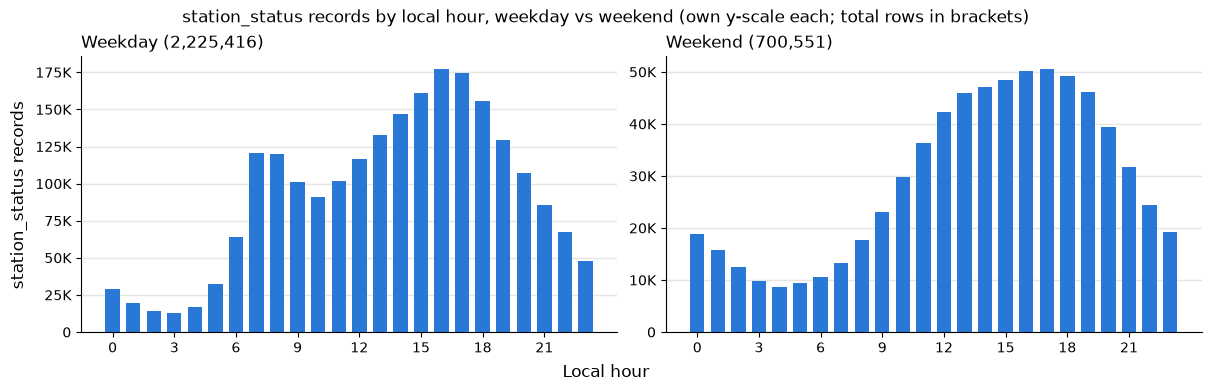

In [27]:
# rows: Weekday / Weekend, columns: local hour 0-23, values: number of station_status rows
hour_by_day_type = (
    station_status.groupby([day_type, "hour"]).size()
    .unstack(fill_value=0)
    .reindex(index=day_type_order, columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, (dt, counts) in zip(axes, hour_by_day_type.iterrows()):
    draw_hour_bars(ax, counts, dt)
fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, weekday vs weekend (own y-scale each; total rows in brackets)")
plt.show()

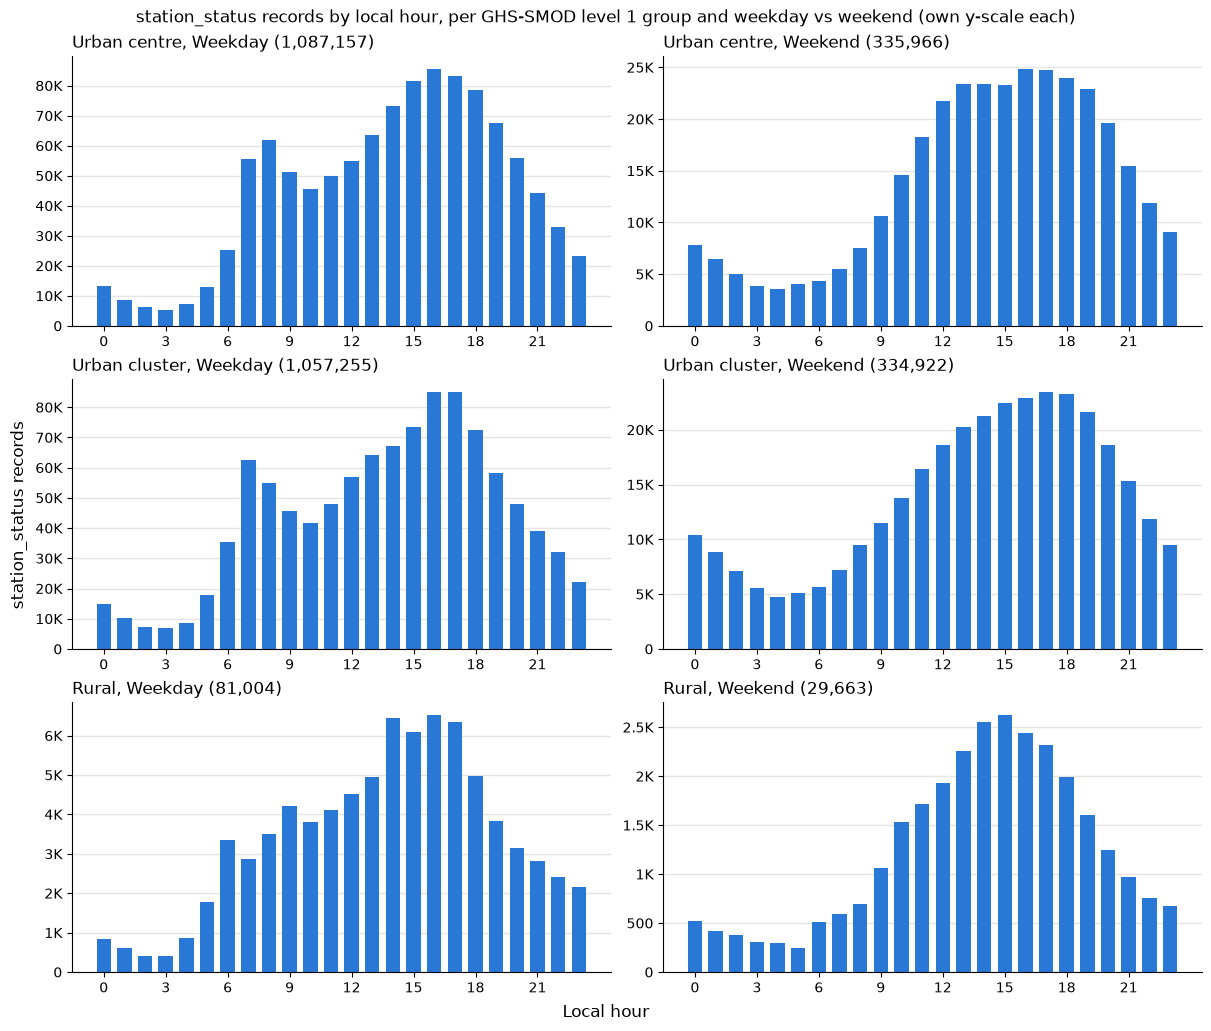

In [28]:
# rows: (smod_level1, day type), columns: local hour 0-23, values: number of station_status rows
hour_by_level1_day_type = (
    station_status.groupby(["smod_level1", day_type, "hour"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

fig, axes = plt.subplots(len(smod_level1_order), 2, figsize=(12, 3.4 * len(smod_level1_order)), layout="constrained")
for r, level in enumerate(smod_level1_order):
    for c, dt in enumerate(day_type_order):
        draw_hour_bars(axes[r, c], hour_by_level1_day_type.loc[(level, dt)], f"{level}, {dt}")
fig.supxlabel("Local hour")
fig.supylabel("station_status records")
fig.suptitle("station_status records by local hour, per GHS-SMOD level 1 group and weekday vs weekend (own y-scale each)")
plt.show()

### Step 19: Factorial analysis (FAMD) of stations

In [29]:
min_weekday_rows = 100   # stations with fewer weekday rows are left out (their shares are mostly noise)
rare_terminal_min = 30   # terminal types with fewer stations are grouped into "other"

status_sorted = station_status.sort_values(["station_id", "time"])
by_station = status_sorted.groupby("station_id")

# Size: time-weighted mean of bikes (each row weighted by the seconds until the station's next row;
# the station's last row has no next row and gets no weight)
seconds_to_next = by_station["time"].shift(-1) - status_sorted["time"]
weighted = status_sorted.assign(w=seconds_to_next, bw=status_sorted["bikes"] * seconds_to_next).dropna(subset=["w"])
mean_bikes = weighted.groupby("station_id")["bw"].sum() / weighted.groupby("station_id")["w"].sum()

# Activity: rows per local date with at least one row, log-transformed (log1p)
active_days = by_station["local_time"].agg(lambda t: t.dt.date.nunique())
rows_per_active_day = by_station.size() / active_days

# Rhythm: share of the station's weekday rows in each 3-hour bin, and share of all rows on weekends
weekday_rows = status_sorted[~status_sorted["is_weekend"]]
hour_bin = (weekday_rows["hour"] // 3).map(lambda b: f"wd_share_{3 * b:02d}_{3 * b + 3:02d}")
weekday_bin_counts = weekday_rows.groupby(["station_id", hour_bin]).size().unstack(fill_value=0)
n_weekday_rows = weekday_bin_counts.sum(axis=1)
weekday_shares = weekday_bin_counts.div(n_weekday_rows, axis=0)
weekend_share = by_station["is_weekend"].mean()

station_features = pd.DataFrame({
    "bike_racks": stations.set_index("id")["bike_racks"].astype(float),
    "mean_bikes": mean_bikes,
    "log_rows_per_active_day": np.log1p(rows_per_active_day),
}).join(weekday_shares).assign(weekend_share=weekend_share)

# Categorical columns: settlement group, terminal type (missing -> "unknown", rare types -> "other"),
# country (descriptive only)
station_info = stations.set_index("id")
terminal_type = station_info["terminal_type"].fillna("unknown")
terminal_counts = terminal_type.value_counts()
station_features["smod_level1"] = station_info["smod_level1"]
station_features["terminal_type"] = terminal_type.where(terminal_type.map(terminal_counts) >= rare_terminal_min, "other")
station_features["country"] = station_info["city_id"].map(cities.set_index("id")["country"])

# Keep stations with enough weekday rows
n_before = len(station_features)
station_features = station_features[n_weekday_rows.reindex(station_features.index).fillna(0) >= min_weekday_rows]
station_features.index.name = "station_id"
print("Stations before:", n_before, "| kept:", len(station_features), "| left out:", n_before - len(station_features))
print("Missing values per column:\n", station_features.isna().sum()[lambda s: s > 0])
print(station_features.shape)
station_features.describe(include="all").T

Stations before: 2899 | kept: 2243 | left out: 656
Missing values per column:
 Series([], dtype: int64)
(2243, 15)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
bike_racks,2243.0,NaN,NaN,NaN,6.528756,6.438929,0.0,0.0,6.0,12.0,56.0
mean_bikes,2243.0,NaN,NaN,NaN,4.353679,4.322019,0.053516,2.379849,3.65323,5.447288,107.979477
log_rows_per_active_day,2243.0,NaN,NaN,NaN,1.806768,0.688562,0.918158,1.295442,1.604278,2.146677,4.97124
wd_share_00_03,2243.0,NaN,NaN,NaN,0.033605,0.029797,0.0,0.012517,0.025761,0.045064,0.289655
wd_share_03_06,2243.0,NaN,NaN,NaN,0.028132,0.037379,0.0,0.006318,0.01626,0.035132,0.391304
wd_share_06_09,2243.0,NaN,NaN,NaN,0.126991,0.075283,0.0,0.073648,0.113141,0.164118,0.506667
wd_share_09_12,2243.0,NaN,NaN,NaN,0.140587,0.057528,0.007634,0.101894,0.130641,0.168763,0.471074
wd_share_12_15,2243.0,NaN,NaN,NaN,0.175792,0.058698,0.0,0.13766,0.169591,0.207901,0.520737
wd_share_15_18,2243.0,NaN,NaN,NaN,0.228357,0.06305,0.041096,0.187602,0.223958,0.263273,0.617913
wd_share_18_21,2243.0,NaN,NaN,NaN,0.17496,0.065458,0.0,0.131888,0.171554,0.215605,0.451977


In [30]:
famd_numeric = ["bike_racks", "mean_bikes", "log_rows_per_active_day",
                *[c for c in station_features.columns if c.startswith("wd_share_")], "weekend_share"]
famd_categorical = ["smod_level1", "terminal_type"]   # active: shape the axes
famd_supplementary = ["country"]                      # projected afterwards, does not shape the axes

famd_input = station_features[famd_numeric + famd_categorical + famd_supplementary]
famd = prince.FAMD(n_components=10, n_iter=5, random_state=42,
                   categorical_columns=famd_categorical + famd_supplementary)
famd = famd.fit(famd_input, supplementary_columns=famd_supplementary)

# share of variance per axis
display(famd.eigenvalues_summary)

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,2.669,12.13%,12.13%
1,2.273,10.33%,22.47%
2,1.701,7.73%,30.20%
3,1.525,6.93%,37.13%
4,1.223,5.56%,42.69%
5,1.120,5.09%,47.78%
6,1.110,5.05%,52.83%
7,1.044,4.75%,57.57%
8,1.012,4.60%,62.17%


In [31]:
# contribution (%) of each active variable to the first 4 axes
display((famd.variable_contributions_.iloc[:, :4] * 100).round(1))

# station coordinates on the axes
station_coords = famd.row_coordinates(famd_input)
station_coords.iloc[:, :4].head()

component,0,1,2,3
variable,,,,
bike_racks,12.1,15.1,0.6,3.5
mean_bikes,1.4,4.9,2.7,3.3
log_rows_per_active_day,7.3,15.2,0.5,2.2
wd_share_00_03,2.7,16.5,0.4,10.3
wd_share_03_06,0.4,5.6,0.2,25.1
wd_share_06_09,14.4,1.8,10.7,4.8
wd_share_09_12,3.4,0.1,28.2,1.8
wd_share_12_15,0.8,2.4,25.5,0.1
wd_share_15_18,0.9,8.6,11.0,4.0


component,0,1,2,3
station_id,,,,
522,-1.586533,-0.365096,1.828052,-2.830766
556,0.356294,-1.330053,1.291502,-3.056352
1450,-0.632416,0.321482,2.517595,-3.509439
6245,-1.761108,-0.325902,3.356725,-3.154569
7418,-2.798588,0.051335,-1.505775,-0.265041


### Step 20: Distance of each station from its city centre

In [32]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two points given in degrees."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))

city_centre = cities.set_index("id")[["lat", "lon"]]
stations["dist_centre_km"] = haversine_km(
    stations["lat"], stations["lon"],
    stations["city_id"].map(city_centre["lat"]), stations["city_id"].map(city_centre["lon"]),
)

print("Stations without a distance:", stations["dist_centre_km"].isna().sum())
display(stations["dist_centre_km"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]))

# 5 stations farthest from their city centre
stations.nlargest(5, "dist_centre_km")[["id", "name", "city_id", "lat", "lon", "dist_centre_km"]]

Stations without a distance: 0


count    2899.000000
mean        6.673006
std        92.414796
min         0.004037
25%         0.927257
50%         1.984835
75%         4.704680
90%        11.603493
99%        69.489590
max      4945.226052
Name: dist_centre_km, dtype: float64

,id,name,city_id,lat,lon,dist_centre_km
2454,205113328,Auf dem Sonnenhügel,858,7.745476,7.801357,4945.226052
314,77079174,DJH - Jugendherberge Prora 57102,775,54.451266,13.569134,114.469983
157,76245743,DJH - Jugendherberge Prora 01,775,54.451273,13.569113,114.469675
202,76246101,DJH - Jugendherberge Sellin 57105 01,775,54.372193,13.700579,114.112424
315,77079526,DJH - Jugendherberge Sellin 57106,775,54.372193,13.700579,114.112424


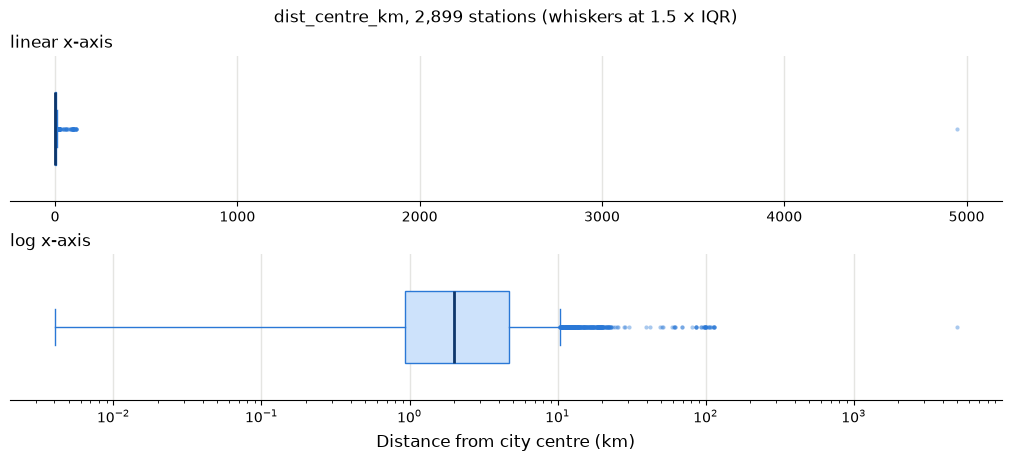

In [33]:
dist = stations["dist_centre_km"].dropna()
box_style = dict(orientation="horizontal", widths=0.5, patch_artist=True,
                 boxprops=dict(facecolor="#cde2fb", edgecolor="#2a78d6"),
                 medianprops=dict(color="#0d366b", linewidth=2),
                 whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"),
                 flierprops=dict(marker="o", markersize=3, markerfacecolor="#2a78d6",
                                 markeredgecolor="none", alpha=0.4))

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), layout="constrained")
for ax, scale in zip(axes, ["linear", "log"]):
    ax.boxplot(dist, **box_style)
    ax.set_xscale(scale)
    ax.set_yticks([])
    ax.set_title(f"{scale} x-axis", loc="left")
    ax.grid(axis="x", color="#e5e5e2", linewidth=1)
    ax.spines[["top", "right", "left"]].set_visible(False)
fig.supxlabel("Distance from city centre (km)")
fig.suptitle(f"dist_centre_km, {len(dist):,} stations (whiskers at 1.5 × IQR)")
plt.show()

### Step 21: Remove station 205113328 (Tecklenburg)

The boxplot shows this station as an outlier; its coordinates are probably wrong data, so it is removed.

In [34]:
bad_station_ids = [205113328]   # Tecklenburg station with lat 7.75 (outlier in Step 20)

print(stations.loc[stations["id"].isin(bad_station_ids), ["id", "name", "city_id", "lat", "lon", "dist_centre_km"]])

n_stations, n_status = len(stations), len(station_status)
stations = stations[~stations["id"].isin(bad_station_ids)]
station_status = station_status[~station_status["station_id"].isin(bad_station_ids)]

print("stations rows:", n_stations, "->", len(stations))
print("station_status rows:", n_status, "->", len(station_status))
stations["dist_centre_km"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

             id                 name  city_id       lat       lon  \
2454  205113328  Auf dem Sonnenhügel      858  7.745476  7.801357   

      dist_centre_km  
2454     4945.226052  
stations rows: 2899 -> 2898
station_status rows: 2925967 -> 2925958


count    2898.000000
mean        4.968881
std        11.032809
min         0.004037
25%         0.926940
50%         1.984592
75%         4.693935
90%        11.586952
99%        69.242005
max       114.469983
Name: dist_centre_km, dtype: float64

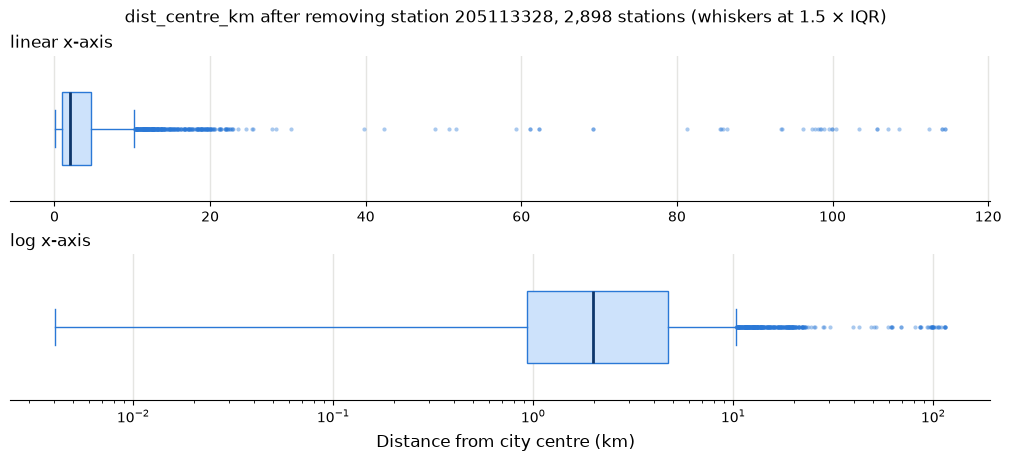

In [35]:
# same boxplot as Step 20 (uses box_style from Step 20), after the removal
dist = stations["dist_centre_km"].dropna()

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), layout="constrained")
for ax, scale in zip(axes, ["linear", "log"]):
    ax.boxplot(dist, **box_style)
    ax.set_xscale(scale)
    ax.set_yticks([])
    ax.set_title(f"{scale} x-axis", loc="left")
    ax.grid(axis="x", color="#e5e5e2", linewidth=1)
    ax.spines[["top", "right", "left"]].set_visible(False)
fig.supxlabel("Distance from city centre (km)")
fig.suptitle(f"dist_centre_km after removing station 205113328, {len(dist):,} stations (whiskers at 1.5 × IQR)")
plt.show()

### Step 22: PCA on station flow signatures and distance from the centre

In [36]:
min_departures = 100   # stations need at least this many departures ...
min_arrivals = 100     # ... and this many arrivals (all days together)
smoothing = 3          # added to every bin count before computing shares

status_sorted = station_status.sort_values(["station_id", "time"])

# change in bikes since the station's previous row: a drop = departures, a rise = arrivals
bike_change = status_sorted.groupby("station_id")["bikes"].diff()
moves = pd.DataFrame({
    "station_id": status_sorted["station_id"],
    "day_type": np.where(status_sorted["is_weekend"], "we", "wd"),
    "hour_bin": (status_sorted["hour"] // 3) * 3,
    "departures": (-bike_change).clip(lower=0),
    "arrivals": bike_change.clip(lower=0),
}).dropna()   # the first row of each station has no previous row

counts = moves.groupby(["station_id", "day_type", "hour_bin"])[["departures", "arrivals"]].sum()
counts = counts.unstack(["day_type", "hour_bin"], fill_value=0)

totals = moves.groupby("station_id")[["departures", "arrivals"]].sum()
keep = totals.index[(totals["departures"] >= min_departures) & (totals["arrivals"] >= min_arrivals)]
print("Stations with moves:", len(totals), "| kept:", len(keep), "| left out:", len(totals) - len(keep))

# flow signature per day type and 3-hour bin: share of departures - share of arrivals
flow_columns = {}
for day_type in ["wd", "we"]:
    dep = counts["departures"][day_type].reindex(columns=range(0, 24, 3), fill_value=0).loc[keep] + smoothing
    arr = counts["arrivals"][day_type].reindex(columns=range(0, 24, 3), fill_value=0).loc[keep] + smoothing
    signature = dep.div(dep.sum(axis=1), axis=0) - arr.div(arr.sum(axis=1), axis=0)
    for b in signature.columns:
        flow_columns[f"{day_type}_flow_{b:02d}_{b + 3:02d}"] = signature[b]

station_flows = pd.DataFrame(flow_columns)
station_flows["log_dist_centre"] = np.log1p(stations.set_index("id")["dist_centre_km"]).reindex(station_flows.index)
station_flows.index.name = "station_id"

print("Missing values:", int(station_flows.isna().sum().sum()))
print(station_flows.shape)
station_flows.describe().T.round(3)

Stations with moves: 2891 | kept: 2098 | left out: 793
Missing values: 0
(2098, 17)


,count,mean,std,min,25%,50%,75%,max
wd_flow_00_03,2098.0,-0.004,0.031,-0.208,-0.014,-0.001,0.011,0.295
wd_flow_03_06,2098.0,0.001,0.045,-0.409,-0.007,0.001,0.011,0.428
wd_flow_06_09,2098.0,0.013,0.149,-0.717,-0.040,0.011,0.079,0.659
wd_flow_09_12,2098.0,0.007,0.090,-0.470,-0.036,0.007,0.047,0.611
wd_flow_12_15,2098.0,0.003,0.069,-0.330,-0.036,0.002,0.038,0.482
wd_flow_15_18,2098.0,0.003,0.131,-0.595,-0.063,-0.004,0.057,0.658
wd_flow_18_21,2098.0,-0.012,0.077,-0.541,-0.050,-0.011,0.029,0.634
wd_flow_21_24,2098.0,-0.011,0.063,-0.466,-0.043,-0.008,0.020,0.269
we_flow_00_03,2098.0,-0.011,0.059,-0.297,-0.037,-0.006,0.017,0.315
we_flow_03_06,2098.0,-0.005,0.040,-0.256,-0.018,-0.001,0.011,0.265


In [37]:
pca_columns = list(station_flows.columns)
pca_input = StandardScaler().fit_transform(station_flows[pca_columns])
pca = PCA().fit(pca_input)

variance = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "% of variance": pca.explained_variance_ratio_ * 100,
    "cumulative %": pca.explained_variance_ratio_.cumsum() * 100,
}, index=[f"PC{i + 1}" for i in range(pca.n_components_)]).round(2)
display(variance)

# loadings: correlation of each column with the first 4 components
loadings = pd.DataFrame(pca.components_[:4].T * np.sqrt(pca.explained_variance_[:4]),
                        index=pca_columns, columns=["PC1", "PC2", "PC3", "PC4"]).round(2)
loadings

,eigenvalue,% of variance,cumulative %
PC1,3.45,20.31,20.31
PC2,2.24,13.19,33.50
PC3,1.50,8.84,42.34
PC4,1.44,8.44,50.78
PC5,1.11,6.53,57.31
PC6,1.03,6.04,63.35
PC7,0.92,5.44,68.78
PC8,0.89,5.21,73.99
PC9,0.84,4.95,78.94
PC10,0.76,4.48,83.42


,PC1,PC2,PC3,PC4
wd_flow_00_03,-0.43,-0.48,-0.25,-0.01
wd_flow_03_06,0.15,-0.30,-0.17,0.62
wd_flow_06_09,0.59,-0.52,0.37,0.12
wd_flow_09_12,0.66,-0.14,0.07,-0.32
wd_flow_12_15,0.09,0.49,-0.42,-0.29
wd_flow_15_18,-0.46,0.63,-0.32,0.08
wd_flow_18_21,-0.61,0.26,0.21,0.18
wd_flow_21_24,-0.65,-0.28,0.13,-0.32
we_flow_00_03,-0.52,-0.49,-0.27,-0.12
we_flow_03_06,-0.25,-0.40,-0.45,0.42


In [38]:
# station scores on the components, and mean score per group of the descriptive columns
pca_scores = pd.DataFrame(pca.transform(pca_input)[:, :4], index=station_flows.index,
                          columns=["PC1", "PC2", "PC3", "PC4"])

station_info = stations.set_index("id")
descriptive = pd.DataFrame({
    "smod_level1": station_info["smod_level1"],
    "country": station_info["city_id"].map(cities.set_index("id")["country"]),
    "terminal_type": station_info["terminal_type"].fillna("unknown"),
}).reindex(pca_scores.index)

for col in descriptive.columns:
    summary = pca_scores.groupby(descriptive[col]).mean().round(2)
    summary.insert(0, "stations", descriptive[col].value_counts())
    print(f"\nMean component score by {col}")
    display(summary.sort_values("stations", ascending=False))


Mean component score by smod_level1


,stations,PC1,PC2,PC3,PC4
smod_level1,,,,,
Urban cluster,1067,-0.04,0.02,0.06,0.08
Urban centre,903,0.00,0.01,-0.06,-0.00
Rural,128,0.33,-0.20,-0.04,-0.60



Mean component score by country


,stations,PC1,PC2,PC3,PC4
country,,,,,
DE,648,0.09,0.05,0.15,-0.11
PL,577,-0.02,0.06,-0.16,0.11
AT,187,-0.02,-0.22,-0.38,-0.25
CZ,174,-0.20,-0.14,0.11,0.22
CH,146,-0.09,0.32,0.21,0.06
HR,101,0.03,-0.01,0.02,0.10
GB,72,0.44,-0.36,-0.05,0.06
SI,68,-0.39,-0.22,0.12,0.04
ES,64,-0.20,0.02,0.06,0.08



Mean component score by terminal_type


,stations,PC1,PC2,PC3,PC4
terminal_type,,,,,
sign,723,-0.02,-0.05,-0.09,0.10
unknown,395,-0.09,0.04,-0.02,-0.03
7inch,310,-0.07,-0.04,-0.08,0.10
stele,199,0.19,-0.06,-0.02,-0.10
free,166,-0.02,0.05,0.45,-0.39
smart_sign,113,-0.23,-0.21,0.05,0.22
character,94,0.14,0.10,-0.14,0.03
traffic_sign,61,0.98,0.79,0.54,-0.61
mmt,23,-0.02,-0.36,0.38,0.00


### Step 23: Biplot of the Step 22 PCA (PC1 / PC2)

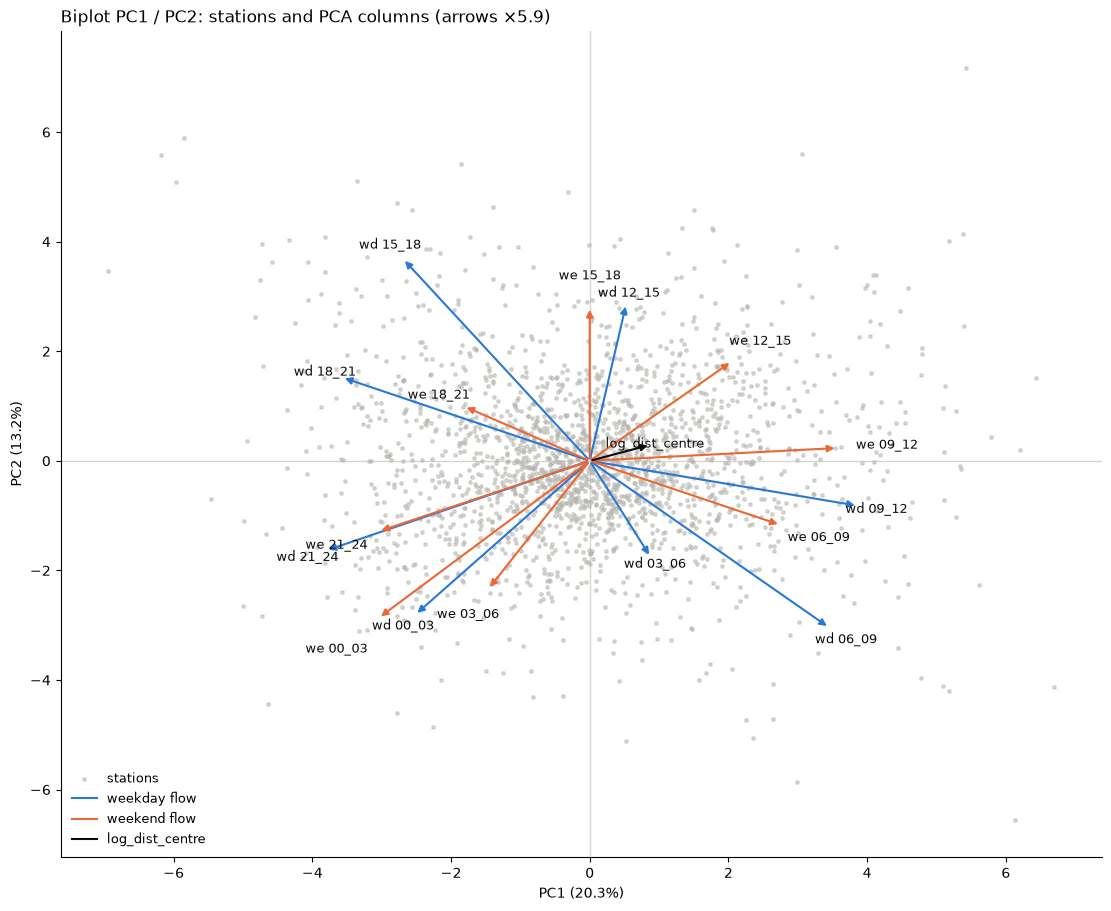

In [39]:
pc_x, pc_y = "PC1", "PC2"
var_x = pca.explained_variance_ratio_[0] * 100
var_y = pca.explained_variance_ratio_[1] * 100

# arrows: loadings, stretched so the longest arrow reaches 90% of the station cloud
arrow_scale = 0.9 * np.abs(pca_scores[[pc_x, pc_y]]).quantile(0.99).max() / np.sqrt((loadings[[pc_x, pc_y]] ** 2).sum(axis=1)).max()

fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ax.scatter(pca_scores[pc_x], pca_scores[pc_y], s=6, color="#b5b4ad", alpha=0.5, label="stations", zorder=1)
for var, (lx, ly) in loadings[[pc_x, pc_y]].iterrows():
    color = "#2a78d6" if var.startswith("wd_") else "#eb6834" if var.startswith("we_") else "#0b0b0b"
    ax.annotate("", xy=(lx * arrow_scale, ly * arrow_scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.5), zorder=3)
    label_pos = 1.20 if var.startswith("we_") else 1.07   # weekend labels further out so they don't overlap
    ax.text(lx * arrow_scale * label_pos, ly * arrow_scale * label_pos, var.replace("_flow_", " "),
            fontsize=9, color="#0b0b0b", ha="center", va="center", zorder=4)

ax.axhline(0, color="#d6d5d0", linewidth=1, zorder=0)
ax.axvline(0, color="#d6d5d0", linewidth=1, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel(f"{pc_x} ({var_x:.1f}%)")
ax.set_ylabel(f"{pc_y} ({var_y:.1f}%)")

# legend entries for the arrow colours
ax.plot([], [], color="#2a78d6", lw=1.5, label="weekday flow")
ax.plot([], [], color="#eb6834", lw=1.5, label="weekend flow")
ax.plot([], [], color="#0b0b0b", lw=1.5, label="log_dist_centre")
ax.legend(loc="lower left", fontsize=9, frameon=False)
ax.set_title(f"Biplot {pc_x} / {pc_y}: stations and PCA columns (arrows ×{arrow_scale:.1f})", loc="left")
plt.show()

### Step 24: K-means on the Step 22 PCA: elbow and silhouette index

In [40]:
# K-means input: station scores on the first components that together explain at least 90% of the variance
n_components = int(np.argmax(pca.explained_variance_ratio_.cumsum() >= 0.90)) + 1
cluster_input = pca.transform(pca_input)[:, :n_components]
print(f"Components used: {n_components} ({pca.explained_variance_ratio_[:n_components].sum() * 100:.1f}% of variance), "
      f"stations: {len(cluster_input)}")

k_values = range(1, 11)
results = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input)
    silhouette = silhouette_score(cluster_input, km.labels_) if k > 1 else np.nan   # undefined for k = 1
    results.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
kmeans_results = pd.DataFrame(results).set_index("k")

# elbow: the k whose point lies farthest from the straight line joining the first and last inertia values
# (both axes rescaled to 0-1 first)
x = (kmeans_results.index - kmeans_results.index.min()) / (kmeans_results.index.max() - kmeans_results.index.min())
y = (kmeans_results["inertia"] - kmeans_results["inertia"].min()) / (kmeans_results["inertia"].max() - kmeans_results["inertia"].min())
distance_to_line = np.abs(x + y - 1) / np.sqrt(2)   # line from (0, 1) to (1, 0)
elbow_k = int(kmeans_results.index[np.argmax(distance_to_line)])
print("Elbow at k =", elbow_k)

kmeans_results.round(3)

Components used: 12 (90.8% of variance), stations: 2098
Elbow at k = 4


,inertia,silhouette
k,,
1,32371.591,NaN
2,28036.257,0.123
3,26251.793,0.102
4,24953.042,0.093
5,23850.973,0.085
6,22969.249,0.096
7,22321.968,0.060
8,21724.811,0.084
9,21159.365,0.078


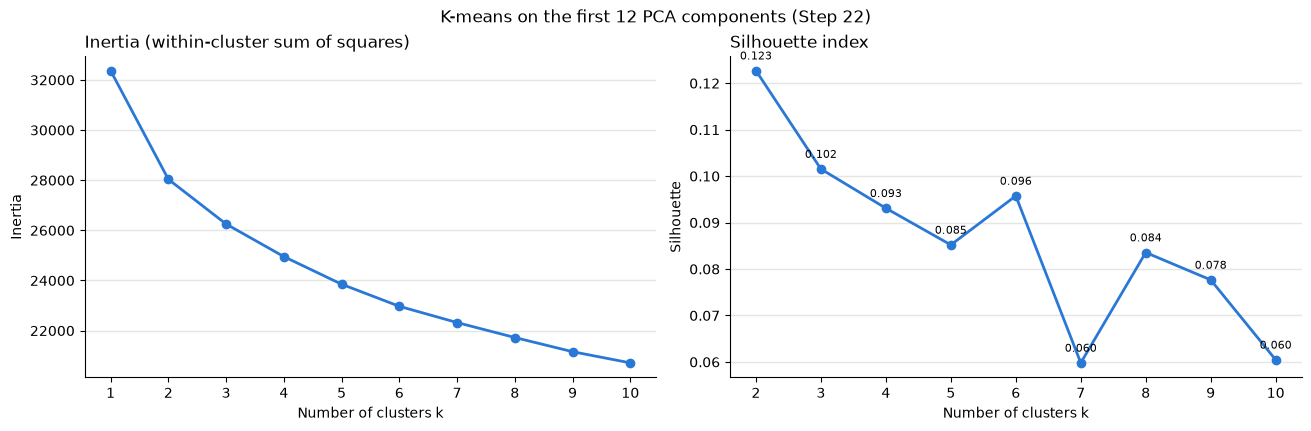

In [41]:
fig, (ax_in, ax_sil) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")

ax_in.plot(kmeans_results.index, kmeans_results["inertia"], color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
ax_in.set_title("Inertia (within-cluster sum of squares)", loc="left")
ax_in.set_ylabel("Inertia")

sil = kmeans_results["silhouette"].dropna()
ax_sil.plot(sil.index, sil.values, color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
for k, v in sil.items():
    ax_sil.annotate(f"{v:.3f}", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax_sil.set_title("Silhouette index", loc="left")
ax_sil.set_ylabel("Silhouette")

for ax in (ax_in, ax_sil):
    ax.set_xticks(list(kmeans_results.index) if ax is ax_in else list(sil.index))
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"K-means on the first {n_components} PCA components (Step 22)")
plt.show()

### Step 25: Correlation matrix of `stations` and the added features

In [42]:
# numerical columns of stations, without identifiers (id, city_id, app_number) and codes (place_type)
station_columns = ["bike_racks", "special_racks", "lon", "lat", "dist_centre_km"]

# added features: Step 19 (station_features, numerical) and Step 22 (station_flows)
step19_columns = [c for c in station_features.select_dtypes("number").columns if c != "bike_racks"]  # bike_racks already above
step22_columns = list(station_flows.columns)

corr_table = (
    stations.set_index("id")[station_columns]
    .join(station_features[step19_columns])
    .join(station_flows[step22_columns])
)
print("Stations:", len(corr_table), "| columns:", corr_table.shape[1])
print("Non-missing values per column:", corr_table.notna().sum().min(), "to", corr_table.notna().sum().max())

# Pearson correlation; each pair uses the stations that have both values
corr_matrix = corr_table.corr(method="pearson")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250):
    display(corr_matrix.round(2))

# pairs ordered by absolute correlation
pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index).rename("correlation").round(2)
pairs.head(20)

Stations: 2898 | columns: 33
Non-missing values per column: 2098 to 2898


,bike_racks,special_racks,lon,lat,dist_centre_km,mean_bikes,log_rows_per_active_day,wd_share_00_03,wd_share_03_06,wd_share_06_09,wd_share_09_12,wd_share_12_15,wd_share_15_18,wd_share_18_21,wd_share_21_24,weekend_share,wd_flow_00_03,wd_flow_03_06,wd_flow_06_09,wd_flow_09_12,wd_flow_12_15,wd_flow_15_18,wd_flow_18_21,wd_flow_21_24,we_flow_00_03,we_flow_03_06,we_flow_06_09,we_flow_09_12,we_flow_12_15,we_flow_15_18,we_flow_18_21,we_flow_21_24,log_dist_centre
bike_racks,1.00,-0.02,0.18,0.17,0.05,0.29,0.50,-0.05,-0.00,-0.18,-0.08,0.05,0.08,0.14,0.06,0.14,0.08,0.01,-0.03,-0.04,0.01,0.01,0.03,0.03,0.07,0.08,-0.05,-0.01,-0.02,0.03,-0.07,-0.00,-0.09
special_racks,-0.02,1.00,-0.02,0.05,0.01,-0.01,-0.01,0.05,0.03,-0.03,-0.02,-0.02,0.00,0.02,0.01,0.07,0.00,-0.01,0.00,-0.01,-0.01,-0.00,-0.01,0.02,0.01,0.02,0.01,-0.03,0.01,-0.01,-0.01,0.02,0.00
lon,0.18,-0.02,1.00,-0.01,-0.04,0.02,0.04,0.06,0.01,-0.18,-0.19,0.02,0.13,0.11,0.11,0.16,0.07,0.01,-0.03,-0.02,0.06,-0.02,0.01,0.01,0.03,0.05,-0.01,-0.02,0.05,0.03,-0.07,-0.04,0.01
lat,0.17,0.05,-0.01,1.00,0.07,0.12,0.01,0.06,0.20,0.00,-0.18,-0.06,0.09,0.00,-0.04,0.12,0.01,-0.03,0.02,0.01,0.01,-0.02,-0.02,0.01,-0.01,-0.02,0.02,-0.01,0.04,0.01,-0.00,-0.03,-0.04
dist_centre_km,0.05,0.01,-0.04,0.07,1.00,0.01,-0.15,0.20,0.02,-0.16,0.03,-0.05,-0.07,0.03,0.18,0.16,-0.07,0.01,0.02,0.09,-0.01,-0.05,-0.01,-0.02,-0.06,-0.06,0.01,0.10,0.01,-0.06,0.01,0.01,0.91
mean_bikes,0.29,-0.01,0.02,0.12,0.01,1.00,0.25,-0.04,0.02,-0.01,0.07,0.01,-0.01,-0.04,-0.02,0.05,0.06,-0.02,0.04,0.13,-0.01,-0.12,-0.06,0.03,0.06,0.01,-0.05,0.06,0.03,-0.12,-0.01,0.03,0.05
log_rows_per_active_day,0.50,-0.01,0.04,0.01,-0.15,0.25,1.00,-0.16,-0.03,-0.04,-0.19,0.05,0.08,0.15,0.05,-0.00,0.04,-0.02,-0.05,-0.02,-0.00,0.03,0.03,0.03,0.08,0.07,-0.07,-0.02,-0.03,0.02,-0.03,0.01,-0.17
wd_share_00_03,-0.05,0.05,0.06,0.06,0.20,-0.04,-0.16,1.00,0.36,-0.25,-0.10,-0.20,-0.29,-0.09,0.34,0.21,-0.13,-0.04,0.07,0.05,0.01,-0.06,-0.00,-0.03,-0.08,-0.05,0.01,-0.02,0.04,0.06,0.03,-0.01,0.24
wd_share_03_06,-0.00,0.03,0.01,0.20,0.02,0.02,-0.03,0.36,1.00,-0.09,-0.18,-0.09,-0.26,-0.20,0.07,-0.01,-0.05,-0.15,0.03,-0.01,0.01,-0.02,0.04,0.04,-0.02,-0.07,0.01,-0.03,0.03,0.02,0.02,0.01,0.04
wd_share_06_09,-0.18,-0.03,-0.18,0.00,-0.16,-0.01,-0.04,-0.25,-0.09,1.00,-0.15,-0.25,0.04,-0.38,-0.39,-0.49,0.02,-0.01,0.02,-0.04,0.00,0.05,-0.06,-0.02,-0.00,-0.02,0.00,-0.02,0.02,-0.01,0.00,0.02,-0.18


dist_centre_km  log_dist_centre            0.91
wd_flow_06_09   wd_flow_15_18             -0.76
bike_racks      log_rows_per_active_day    0.50
wd_share_06_09  weekend_share             -0.49
wd_flow_21_24   we_flow_21_24              0.48
wd_flow_09_12   wd_flow_18_21             -0.47
wd_flow_00_03   we_flow_00_03              0.45
wd_flow_06_09   wd_flow_18_21             -0.44
wd_share_18_21  weekend_share              0.44
wd_flow_09_12   wd_flow_15_18             -0.43
                we_flow_09_12              0.42
wd_share_06_09  wd_share_21_24            -0.39
                wd_share_18_21            -0.38
wd_flow_21_24   we_flow_00_03              0.38
wd_share_00_03  wd_share_03_06             0.36
wd_flow_09_12   wd_flow_21_24             -0.35
wd_share_00_03  wd_share_21_24             0.34
we_flow_09_12   we_flow_21_24             -0.34
wd_share_15_18  wd_share_21_24            -0.33
wd_flow_06_09   wd_flow_12_15             -0.33
Name: correlation, dtype: float64

### Step 26: K-means elbow and silhouette on weekday 6-hour shares

In [43]:
min_weekday_rows_6h = 100   # same threshold as Step 19

# share of each station's weekday rows in 6-hour bins of local hour
weekday_rows_6h = station_status[~station_status["is_weekend"]]
bin_6h = (weekday_rows_6h["hour"] // 6).map(lambda b: f"wd_share_{6 * b:02d}_{6 * b + 6:02d}")
counts_6h = weekday_rows_6h.groupby(["station_id", bin_6h]).size().unstack(fill_value=0)
counts_6h = counts_6h[counts_6h.sum(axis=1) >= min_weekday_rows_6h]
wd_share_6h = counts_6h.div(counts_6h.sum(axis=1), axis=0)

print("Stations kept:", len(wd_share_6h))
wd_share_6h.describe().T.round(3)

Stations kept: 2243


,count,mean,std,min,25%,50%,75%,max
hour,,,,,,,,
wd_share_00_06,2243.0,0.062,0.056,0.000,0.026,0.047,0.080,0.510
wd_share_06_12,2243.0,0.268,0.087,0.029,0.206,0.260,0.323,0.628
wd_share_12_18,2243.0,0.404,0.078,0.070,0.353,0.404,0.453,0.709
wd_share_18_24,2243.0,0.267,0.092,0.000,0.210,0.264,0.324,0.691


In [44]:
# same procedure as Steps 22 and 24: standardise -> PCA -> components up to 90% -> K-means for k = 1..10
pca_input_6h = StandardScaler().fit_transform(wd_share_6h)
pca_6h = PCA().fit(pca_input_6h)
display(pd.DataFrame({
    "% of variance": pca_6h.explained_variance_ratio_ * 100,
    "cumulative %": pca_6h.explained_variance_ratio_.cumsum() * 100,
}, index=[f"PC{i + 1}" for i in range(pca_6h.n_components_)]).round(2))

n_components_6h = int(np.argmax(pca_6h.explained_variance_ratio_.cumsum() >= 0.90)) + 1
cluster_input_6h = pca_6h.transform(pca_input_6h)[:, :n_components_6h]
print(f"Components used: {n_components_6h} ({pca_6h.explained_variance_ratio_[:n_components_6h].sum() * 100:.1f}% of variance)")

results_6h = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_6h)
    silhouette = silhouette_score(cluster_input_6h, km.labels_) if k > 1 else np.nan   # undefined for k = 1
    results_6h.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
kmeans_results_6h = pd.DataFrame(results_6h).set_index("k")

# elbow: same rule as Step 24
x = (kmeans_results_6h.index - 1) / 9
y = (kmeans_results_6h["inertia"] - kmeans_results_6h["inertia"].min()) / (kmeans_results_6h["inertia"].max() - kmeans_results_6h["inertia"].min())
elbow_k_6h = int(kmeans_results_6h.index[np.argmax(np.abs(x + y - 1) / np.sqrt(2))])
print("Elbow at k =", elbow_k_6h)

kmeans_results_6h.round(3)

,% of variance,cumulative %
PC1,45.87,45.87
PC2,30.93,76.80
PC3,23.20,100.00
PC4,0.00,100.00


Components used: 3 (100.0% of variance)
Elbow at k = 4


,inertia,silhouette
k,,
1,8972.000,NaN
2,6456.307,0.262
3,5109.356,0.282
4,4135.142,0.268
5,3555.054,0.263
6,3192.416,0.254
7,2881.923,0.261
8,2619.953,0.246
9,2417.687,0.249


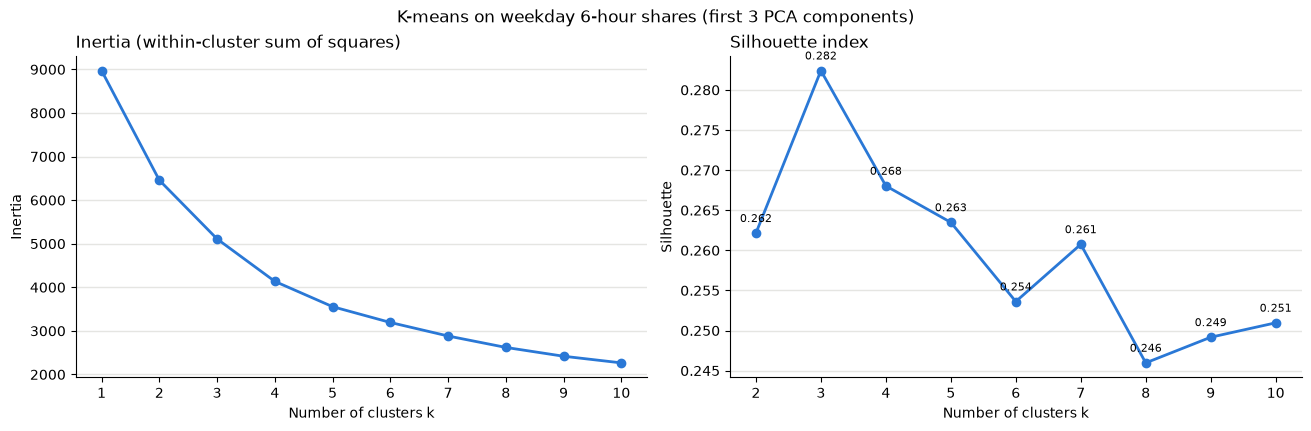

In [45]:
fig, (ax_in, ax_sil) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")

ax_in.plot(kmeans_results_6h.index, kmeans_results_6h["inertia"], color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
ax_in.set_title("Inertia (within-cluster sum of squares)", loc="left")
ax_in.set_ylabel("Inertia")

sil_6h = kmeans_results_6h["silhouette"].dropna()
ax_sil.plot(sil_6h.index, sil_6h.values, color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
for k, v in sil_6h.items():
    ax_sil.annotate(f"{v:.3f}", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax_sil.set_title("Silhouette index", loc="left")
ax_sil.set_ylabel("Silhouette")

for ax in (ax_in, ax_sil):
    ax.set_xticks(list(kmeans_results_6h.index) if ax is ax_in else list(sil_6h.index))
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"K-means on weekday 6-hour shares (first {n_components_6h} PCA components)")
plt.show()

### Step 27: FAMD with weekday 6-hour shares, K-means elbow and silhouette

`terminal_type` is removed for now.

In [46]:
# Step 19 features with the 3-hour weekday shares replaced by the 6-hour shares of Step 26
famd_numeric_6h = ["bike_racks", "mean_bikes", "log_rows_per_active_day", *wd_share_6h.columns, "weekend_share"]
famd_categorical_6h = ["smod_level1", "terminal_type"]   # active
famd_supplementary_6h = ["country"]                      # projected afterwards only

famd_input_6h = (
    station_features[["bike_racks", "mean_bikes", "log_rows_per_active_day", "weekend_share",
                      *famd_categorical_6h, *famd_supplementary_6h]]
    .join(wd_share_6h, how="inner")
)[famd_numeric_6h + famd_categorical_6h + famd_supplementary_6h]
print("Stations:", len(famd_input_6h))

# number of dimensions: numerical columns + (categories - 1) per active categorical column
n_dims_6h = len(famd_numeric_6h) + sum(famd_input_6h[c].nunique() - 1 for c in famd_categorical_6h)
famd_6h = prince.FAMD(n_components=n_dims_6h, n_iter=5, random_state=42,
                      categorical_columns=famd_categorical_6h + famd_supplementary_6h)
famd_6h = famd_6h.fit(famd_input_6h, supplementary_columns=famd_supplementary_6h)
display(famd_6h.eigenvalues_summary.head(10))

# contribution (%) of each active variable to the first 4 axes
display((famd_6h.variable_contributions_.iloc[:, :4] * 100).round(1))

Stations: 2243


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,2.569,14.27%,14.27%
1,2.060,11.45%,25.72%
2,1.313,7.30%,33.02%
3,1.244,6.91%,39.93%
4,1.141,6.34%,46.27%
5,1.043,5.79%,52.06%
6,1.028,5.71%,57.78%
7,1.002,5.57%,63.34%
8,0.983,5.46%,68.80%


component,0,1,2,3
variable,,,,
bike_racks,19.5,10.0,1.3,0.3
mean_bikes,2.8,5.0,3.9,15.3
log_rows_per_active_day,13.4,9.7,0.3,1.4
wd_share_00_06,0.4,11.5,11.3,0.6
wd_share_06_12,17.6,7.5,7.1,5.2
wd_share_12_18,0.1,16.4,23.9,9.1
wd_share_18_24,15.5,15.8,0.2,0.0
weekend_share,10.2,9.6,8.3,0.8
smod_level1,3.2,1.7,17.6,26.5


In [47]:
# same procedure as Steps 24 and 26: axes up to 90% of the variance -> K-means for k = 1..10
famd_coords_6h = famd_6h.row_coordinates(famd_input_6h)
cumulative = famd_6h.cumulative_percentage_of_variance_ / 100
n_axes_6h = int(np.argmax(np.asarray(cumulative) >= 0.90)) + 1
cluster_input_famd_6h = famd_coords_6h.iloc[:, :n_axes_6h].to_numpy()
print(f"Axes used: {n_axes_6h} ({cumulative[n_axes_6h - 1] * 100:.1f}% of variance)")

results_famd_6h = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_famd_6h)
    silhouette = silhouette_score(cluster_input_famd_6h, km.labels_) if k > 1 else np.nan   # undefined for k = 1
    results_famd_6h.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
kmeans_results_famd_6h = pd.DataFrame(results_famd_6h).set_index("k")

# elbow: same rule as Step 24
x = (kmeans_results_famd_6h.index - 1) / 9
y = (kmeans_results_famd_6h["inertia"] - kmeans_results_famd_6h["inertia"].min()) / (kmeans_results_famd_6h["inertia"].max() - kmeans_results_famd_6h["inertia"].min())
elbow_k_famd_6h = int(kmeans_results_famd_6h.index[np.argmax(np.abs(x + y - 1) / np.sqrt(2))])
print("Elbow at k =", elbow_k_famd_6h)

kmeans_results_famd_6h.round(3)

Axes used: 14 (92.5% of variance)
Elbow at k = 3


,inertia,silhouette
k,,
1,37355.866,NaN
2,33435.000,0.118
3,31039.070,0.136
4,28780.209,0.164
5,26547.580,0.185
6,24352.577,0.217
7,22131.472,0.225
8,19851.574,0.259
9,17615.983,0.292


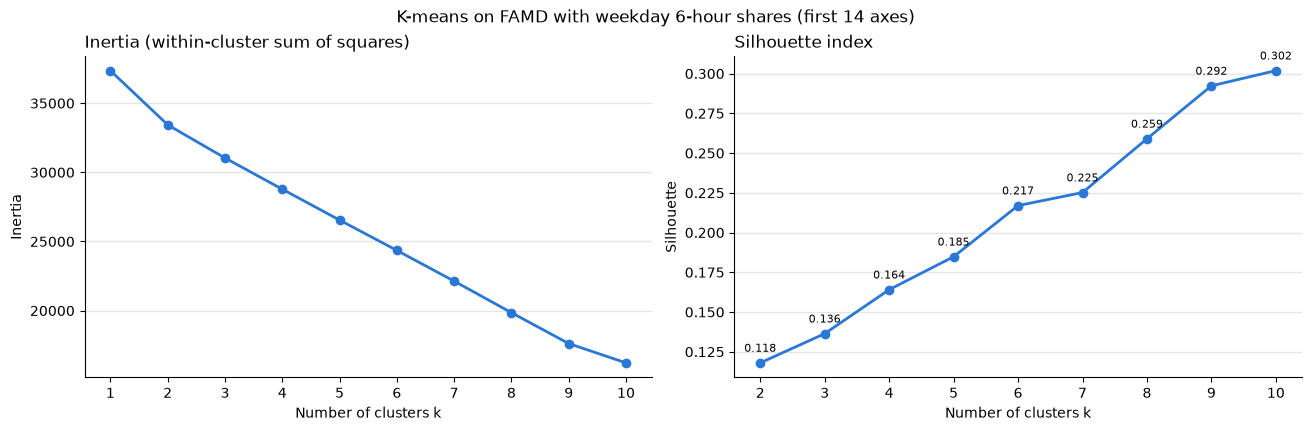

In [48]:
fig, (ax_in, ax_sil) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")

ax_in.plot(kmeans_results_famd_6h.index, kmeans_results_famd_6h["inertia"], color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
ax_in.set_title("Inertia (within-cluster sum of squares)", loc="left")
ax_in.set_ylabel("Inertia")

sil_famd_6h = kmeans_results_famd_6h["silhouette"].dropna()
ax_sil.plot(sil_famd_6h.index, sil_famd_6h.values, color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
for k, v in sil_famd_6h.items():
    ax_sil.annotate(f"{v:.3f}", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax_sil.set_title("Silhouette index", loc="left")
ax_sil.set_ylabel("Silhouette")

for ax in (ax_in, ax_sil):
    ax.set_xticks(list(kmeans_results_famd_6h.index) if ax is ax_in else list(sil_famd_6h.index))
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"K-means on FAMD with weekday 6-hour shares (first {n_axes_6h} axes)")
plt.show()

In [49]:
# how closely the K-means clusters follow terminal_type (ARI: 1 = identical grouping, 0 = unrelated)
for k in (4, 10):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(cluster_input_famd_6h)
    ct = pd.crosstab(labels, famd_input_6h["terminal_type"])
    print(f"k = {k}: ARI with terminal_type = {adjusted_rand_score(famd_input_6h['terminal_type'], labels):.2f}")
    display(pd.DataFrame({
        "stations": ct.sum(axis=1),
        "largest terminal_type": ct.idxmax(axis=1),
        "share of that type": (ct.max(axis=1) / ct.sum(axis=1)).round(2),
    }).rename_axis("cluster"))

k = 4: ARI with terminal_type = 0.21


,stations,largest terminal_type,share of that type
cluster,,,
0,966,sign,0.41
1,187,free,1.00
2,1012,unknown,0.40
3,78,traffic_sign,1.00


k = 10: ARI with terminal_type = 0.91


,stations,largest terminal_type,share of that type
cluster,,,
0,385,unknown,1.00
1,102,character,1.00
2,707,sign,1.00
3,196,stele,1.00
4,124,unknown,0.32
5,78,traffic_sign,1.00
6,181,free,1.00
7,124,smart_sign,1.00
8,306,7inch,0.97


### Step 28: FAMD without `terminal_type`, K-means elbow and silhouette

In [50]:
# Step 27 FAMD without terminal_type
famd_numeric_nt = ["bike_racks", "mean_bikes", "log_rows_per_active_day", *wd_share_6h.columns, "weekend_share"]
famd_categorical_nt = ["smod_level1"]   # active
famd_supplementary_nt = ["country"]     # projected afterwards only

famd_input_nt = (
    station_features[["bike_racks", "mean_bikes", "log_rows_per_active_day", "weekend_share",
                      *famd_categorical_nt, *famd_supplementary_nt]]
    .join(wd_share_6h, how="inner")
)[famd_numeric_nt + famd_categorical_nt + famd_supplementary_nt]
print("Stations:", len(famd_input_nt))

# number of dimensions: numerical columns + (categories - 1) per active categorical column
n_dims_nt = len(famd_numeric_nt) + sum(famd_input_nt[c].nunique() - 1 for c in famd_categorical_nt)
famd_nt = prince.FAMD(n_components=n_dims_nt, n_iter=5, random_state=42,
                      categorical_columns=famd_categorical_nt + famd_supplementary_nt)
famd_nt = famd_nt.fit(famd_input_nt, supplementary_columns=famd_supplementary_nt)
display(famd_nt.eigenvalues_summary)

# contribution (%) of each active variable to the first 4 axes
display((famd_nt.variable_contributions_.iloc[:, :4] * 100).round(1))

Stations: 2243


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,2.296,22.96%,22.96%
1,1.824,18.24%,41.21%
2,1.225,12.25%,53.46%
3,1.134,11.34%,64.80%
4,0.936,9.36%,74.16%
5,0.916,9.16%,83.32%
6,0.667,6.67%,89.99%
7,0.559,5.59%,95.58%
8,0.442,4.42%,100.00%


component,0,1,2,3
variable,,,,
bike_racks,10.0,22.8,1.6,0.1
mean_bikes,1.2,12.4,15.0,14.7
log_rows_per_active_day,6.3,24.3,1.1,3.0
wd_share_00_06,2.9,10.3,18.8,0.1
wd_share_06_12,26.7,0.5,13.8,0.0
wd_share_12_18,3.1,16.3,38.2,1.2
wd_share_18_24,28.8,4.6,0.8,1.5
weekend_share,19.2,2.7,3.9,9.8
smod_level1,1.9,6.0,6.8,69.6


In [51]:
# same procedure as Steps 24, 26 and 27: axes up to 90% of the variance -> K-means for k = 1..10
famd_coords_nt = famd_nt.row_coordinates(famd_input_nt)
cumulative_nt = np.asarray(famd_nt.cumulative_percentage_of_variance_) / 100
n_axes_nt = int(np.argmax(cumulative_nt >= 0.90)) + 1
cluster_input_famd_nt = famd_coords_nt.iloc[:, :n_axes_nt].to_numpy()
print(f"Axes used: {n_axes_nt} ({cumulative_nt[n_axes_nt - 1] * 100:.1f}% of variance)")

results_famd_nt = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_famd_nt)
    silhouette = silhouette_score(cluster_input_famd_nt, km.labels_) if k > 1 else np.nan   # undefined for k = 1
    results_famd_nt.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
kmeans_results_famd_nt = pd.DataFrame(results_famd_nt).set_index("k")

# elbow: same rule as Step 24
x = (kmeans_results_famd_nt.index - 1) / 9
y = (kmeans_results_famd_nt["inertia"] - kmeans_results_famd_nt["inertia"].min()) / (kmeans_results_famd_nt["inertia"].max() - kmeans_results_famd_nt["inertia"].min())
elbow_k_famd_nt = int(kmeans_results_famd_nt.index[np.argmax(np.abs(x + y - 1) / np.sqrt(2))])
print("Elbow at k =", elbow_k_famd_nt)

kmeans_results_famd_nt.round(3)

Axes used: 8 (95.6% of variance)
Elbow at k = 4


,inertia,silhouette
k,,
1,21439.401,NaN
2,18099.507,0.160
3,15968.358,0.161
4,13922.164,0.180
5,12716.129,0.185
6,11700.724,0.184
7,10820.022,0.178
8,10149.977,0.174
9,9648.260,0.165


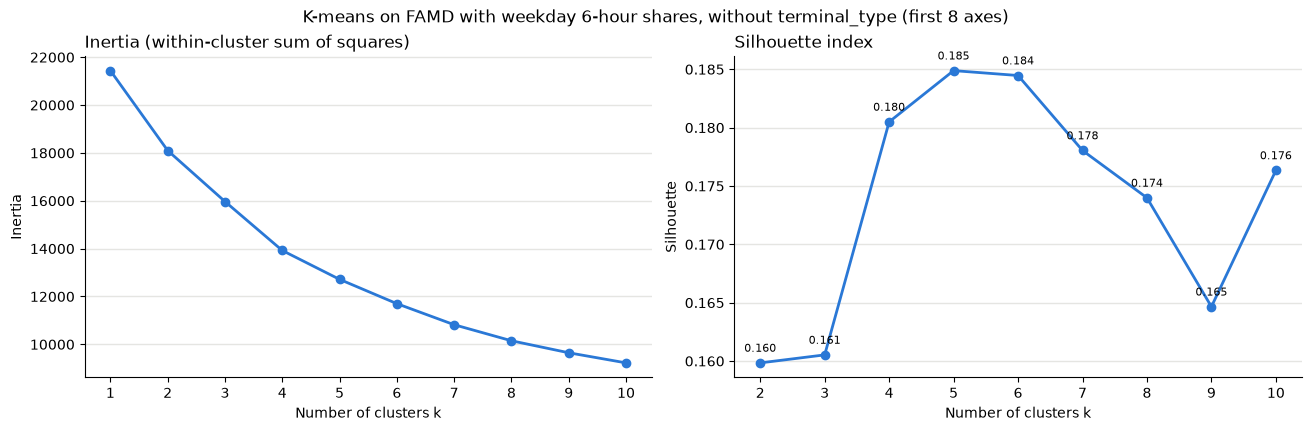

In [52]:
fig, (ax_in, ax_sil) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")

ax_in.plot(kmeans_results_famd_nt.index, kmeans_results_famd_nt["inertia"], color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
ax_in.set_title("Inertia (within-cluster sum of squares)", loc="left")
ax_in.set_ylabel("Inertia")

sil_famd_nt = kmeans_results_famd_nt["silhouette"].dropna()
ax_sil.plot(sil_famd_nt.index, sil_famd_nt.values, color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
for k, v in sil_famd_nt.items():
    ax_sil.annotate(f"{v:.3f}", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax_sil.set_title("Silhouette index", loc="left")
ax_sil.set_ylabel("Silhouette")

for ax in (ax_in, ax_sil):
    ax.set_xticks(list(kmeans_results_famd_nt.index) if ax is ax_in else list(sil_famd_nt.index))
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"K-means on FAMD with weekday 6-hour shares, without terminal_type (first {n_axes_nt} axes)")
plt.show()

### Step 29: K-means with 2, 3, 4 and 5 clusters

In [53]:
# K-means on the Step 28 FAMD axes (cluster_input_famd_nt) for k = 2, 3, 4 and 5
cluster_labels = pd.DataFrame(index=famd_input_nt.index)
for k in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_famd_nt)
    cluster_labels[f"k{k}"] = km.labels_
    print(f"k = {k}: silhouette = {silhouette_score(cluster_input_famd_nt, km.labels_):.3f}")

# number of stations per cluster for each k
display(cluster_labels.apply(lambda col: col.value_counts().sort_index()).fillna(0).astype(int).rename_axis("cluster"))

k = 2: silhouette = 0.160
k = 3: silhouette = 0.161
k = 4: silhouette = 0.180
k = 5: silhouette = 0.185


,k2,k3,k4,k5
cluster,,,,
0,1186,785,140,138
1,1057,605,599,808
2,0,853,695,592
3,0,0,809,702
4,0,0,0,3


In [54]:
# mean of each active numerical column per cluster, and the share of each smod_level1 group per cluster
for k in [2, 3, 4, 5]:
    labels = cluster_labels[f"k{k}"]
    print(f"\nk = {k}")
    profile = famd_input_nt[famd_numeric_nt].groupby(labels).mean().round(3)
    profile.insert(0, "stations", labels.value_counts().sort_index())
    display(profile.rename_axis("cluster"))
    display(pd.crosstab(labels, famd_input_nt["smod_level1"], normalize="index").round(2).rename_axis("cluster"))


k = 2


,stations,bike_racks,mean_bikes,log_rows_per_active_day,wd_share_00_06,wd_share_06_12,wd_share_12_18,wd_share_18_24,weekend_share
cluster,,,,,,,,,
0,1186,9.273,5.054,2.026,0.075,0.214,0.391,0.320,0.285
1,1057,3.449,3.568,1.560,0.047,0.327,0.419,0.207,0.204


smod_level1,Rural,Urban centre,Urban cluster
cluster,,,
0,0.04,0.53,0.43
1,0.08,0.32,0.60



k = 3


,stations,bike_racks,mean_bikes,log_rows_per_active_day,wd_share_00_06,wd_share_06_12,wd_share_12_18,wd_share_18_24,weekend_share
cluster,,,,,,,,,
0,785,3.755,3.650,1.593,0.039,0.339,0.436,0.186,0.187
1,605,13.716,6.297,2.520,0.051,0.223,0.429,0.297,0.277
2,853,3.984,3.622,1.497,0.090,0.233,0.358,0.319,0.281


smod_level1,Rural,Urban centre,Urban cluster
cluster,,,
0,0.09,0.33,0.58
1,0.03,0.67,0.30
2,0.06,0.35,0.59


... (2 outputs left out)

smod_level1,Rural,Urban centre,Urban cluster
cluster,,,
0,1.0,0.00,0.00
1,0.0,0.69,0.31
2,0.0,0.36,0.64
3,0.0,0.37,0.63



k = 5


,stations,bike_racks,mean_bikes,log_rows_per_active_day,wd_share_00_06,wd_share_06_12,wd_share_12_18,wd_share_18_24,weekend_share
cluster,,,,,,,,,
0,138,5.812,5.004,1.601,0.062,0.277,0.416,0.245,0.285
1,808,3.842,3.594,1.488,0.088,0.234,0.359,0.319,0.279
2,592,13.777,5.767,2.519,0.053,0.223,0.427,0.297,0.275
3,702,3.652,3.535,1.608,0.038,0.341,0.435,0.186,0.178
4,3,6.000,91.921,3.038,0.030,0.458,0.363,0.149,0.356


smod_level1,Rural,Urban centre,Urban cluster
cluster,,,
0,1.00,0.00,0.00
1,0.00,0.37,0.63
2,0.00,0.69,0.31
3,0.00,0.35,0.65
4,0.67,0.33,0.00


### Step 30: Scatter plot of the 4 K-means clusters with `smod_level1`

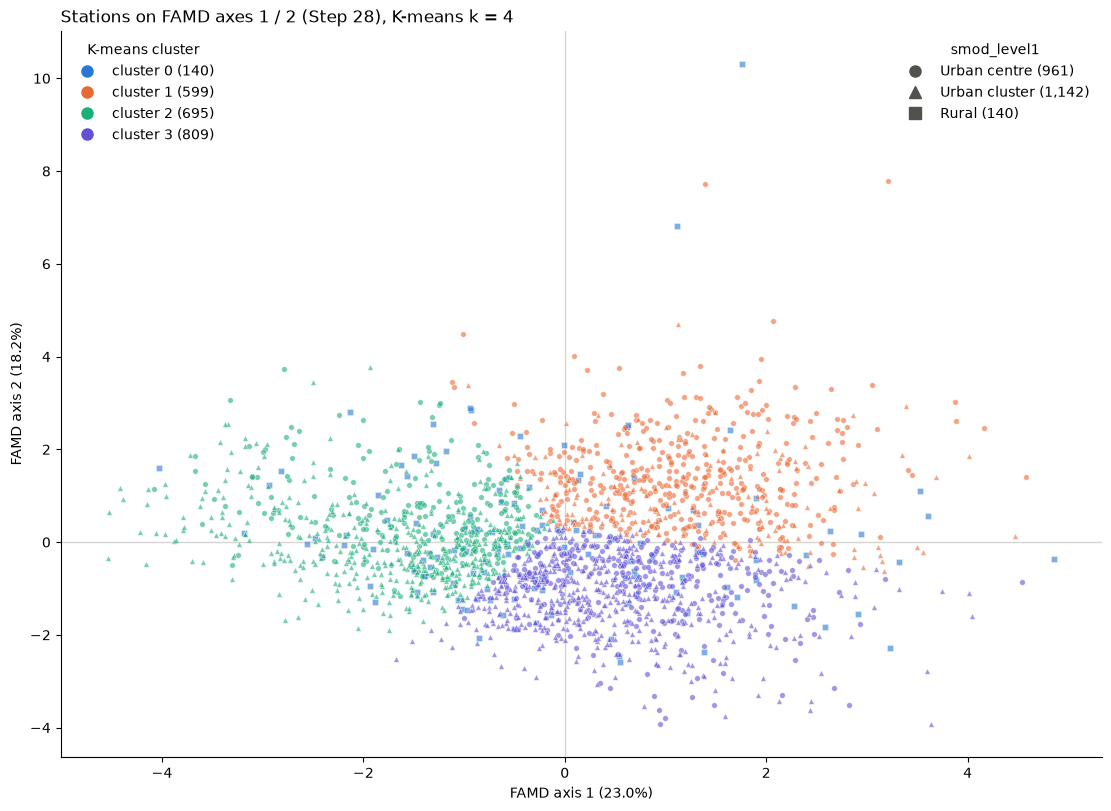

In [55]:
k = 4
labels_k = cluster_labels[f"k{k}"]
coords = famd_coords_nt.iloc[:, :2]                       # FAMD axes 1 and 2 (Step 28)
smod = famd_input_nt["smod_level1"]
var_1, var_2 = np.asarray(famd_nt.percentage_of_variance_)[:2]

cluster_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]   # one colour per cluster
smod_markers = {"Urban centre": "o", "Urban cluster": "^", "Rural": "s"}

fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
for cluster in sorted(labels_k.unique()):
    for group, marker in smod_markers.items():
        mask = (labels_k == cluster) & (smod == group)
        ax.scatter(coords.loc[mask].iloc[:, 0], coords.loc[mask].iloc[:, 1], s=16, marker=marker,
                   color=cluster_colors[cluster], alpha=0.6, edgecolor="white", linewidth=0.4)

ax.axhline(0, color="#d6d5d0", linewidth=1, zorder=0)
ax.axvline(0, color="#d6d5d0", linewidth=1, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel(f"FAMD axis 1 ({var_1:.1f}%)")
ax.set_ylabel(f"FAMD axis 2 ({var_2:.1f}%)")

# two legends: colour = cluster, marker = smod_level1
cluster_handles = [Line2D([], [], marker="o", linestyle="", color=cluster_colors[c], markersize=8,
                          label=f"cluster {c} ({(labels_k == c).sum():,})") for c in sorted(labels_k.unique())]
smod_handles = [Line2D([], [], marker=m, linestyle="", color="#52514e", markersize=8,
                       label=f"{g} ({(smod == g).sum():,})") for g, m in smod_markers.items()]
legend_clusters = ax.legend(handles=cluster_handles, title="K-means cluster", loc="upper left", frameon=False)
ax.add_artist(legend_clusters)
ax.legend(handles=smod_handles, title="smod_level1", loc="upper right", frameon=False)

ax.set_title(f"Stations on FAMD axes 1 / 2 (Step 28), K-means k = {k}", loc="left")
plt.show()

### Step 31: E-bike and normal-bike trips per station

In [56]:
trips = pd.read_csv("./data/trips_small.csv")
bikes = pd.read_csv("./data/bikes.csv")
bike_types_clean = pd.read_csv("./external_data/bike_types_clean.csv")

# propulsion of each trip: bike_id -> bikes.bike_type_id -> bike_types_clean.propulsion_filled
# (propulsion_filled = propulsion_type, with the 30 "unknown" types filled as "human")
bike_propulsion = bikes.set_index("id")["bike_type_id"].map(bike_types_clean.set_index("id")["propulsion_filled"])
trips["propulsion"] = trips["bike_id"].map(bike_propulsion)

# leave out trips without a station at either end
n_trips = len(trips)
trips = trips[trips["station_id_start"].notna() | trips["station_id_end"].notna()]
trips["station_id_start"] = trips["station_id_start"].astype("Int64")
trips["station_id_end"] = trips["station_id_end"].astype("Int64")

print("Trips:", n_trips, "| without any station:", n_trips - len(trips), "| kept:", len(trips))
print("Kept trips without a propulsion value:", trips["propulsion"].isna().sum())
print("With a start station:", trips["station_id_start"].notna().sum(),
      "| with an end station:", trips["station_id_end"].notna().sum())
trips["propulsion"].value_counts(dropna=False)

Trips: 1161376 | without any station: 43405 | kept: 1117971
Kept trips without a propulsion value: 0
With a start station: 1072161 | with an end station: 1039472


propulsion
human              941037
electric_assist    176934
Name: count, dtype: int64

In [57]:
# departures (trip starts) and arrivals (trip ends) per station and propulsion
departures = trips.dropna(subset=["station_id_start"]).groupby(["station_id_start", "propulsion"]).size().unstack(fill_value=0)
arrivals = trips.dropna(subset=["station_id_end"]).groupby(["station_id_end", "propulsion"]).size().unstack(fill_value=0)

trip_activity = pd.DataFrame({
    "dep_ebike": departures.get("electric_assist"),
    "dep_human": departures.get("human"),
    "arr_ebike": arrivals.get("electric_assist"),
    "arr_human": arrivals.get("human"),
}).fillna(0).astype(int)
trip_activity["trips_total"] = trip_activity.sum(axis=1)
trip_activity["ebike_share_dep"] = trip_activity["dep_ebike"] / (trip_activity["dep_ebike"] + trip_activity["dep_human"])
trip_activity["ebike_share_arr"] = trip_activity["arr_ebike"] / (trip_activity["arr_ebike"] + trip_activity["arr_human"])
trip_activity["ebike_share"] = (trip_activity["dep_ebike"] + trip_activity["arr_ebike"]) / trip_activity["trips_total"]
trip_activity["human_share"] = (trip_activity["dep_human"] + trip_activity["arr_human"]) / trip_activity["trips_total"]

# merge into stations (columns dropped first so the cell can be rerun)
stations = stations.drop(columns=trip_activity.columns, errors="ignore").merge(
    trip_activity, left_on="id", right_index=True, how="left")
count_cols = ["dep_ebike", "dep_human", "arr_ebike", "arr_human", "trips_total"]
stations[count_cols] = stations[count_cols].fillna(0).astype(int)   # stations without trips: counts 0, shares NaN

print("Trip station ids not in stations:", (~trip_activity.index.isin(stations["id"])).sum())
print("Stations with at least one trip:", (stations["trips_total"] > 0).sum(), "of", len(stations))
stations[count_cols + ["ebike_share_dep", "ebike_share_arr", "ebike_share", "human_share"]].describe().T.round(3)

Trip station ids not in stations: 1631
Stations with at least one trip: 2859 of 2898


,count,mean,std,min,25%,50%,75%,max
dep_ebike,2898.0,56.119,322.698,0.0,0.0,0.0,0.00,5715.0
dep_human,2898.0,308.082,562.217,0.0,24.0,116.0,348.00,8116.0
arr_ebike,2898.0,47.862,261.349,0.0,0.0,0.0,0.00,4724.0
arr_human,2898.0,284.585,536.045,0.0,21.0,105.0,316.75,7721.0
trips_total,2898.0,696.649,1199.102,0.0,86.0,297.0,776.75,15837.0
ebike_share_dep,2836.0,0.128,0.308,0.0,0.0,0.0,0.00,1.0
ebike_share_arr,2837.0,0.128,0.307,0.0,0.0,0.0,0.00,1.0
ebike_share,2859.0,0.129,0.308,0.0,0.0,0.0,0.00,1.0
human_share,2859.0,0.871,0.308,0.0,1.0,1.0,1.00,1.0


### Step 32: Stations and e-bike / normal-bike trips per urban–rural class

In [58]:
trip_count_cols = ["dep_ebike", "arr_ebike", "dep_human", "arr_human"]
smod_level1_order = ["Urban centre", "Urban cluster", "Rural"]
smod_class_order = ["Urban centre", "Dense urban cluster", "Semi-dense urban cluster", "Suburban or peri-urban",
                    "Rural cluster", "Low density rural", "Very low density rural"]

def counts_by(group_col, order):
    """Number of stations and summed e-bike / human departures and arrivals per group, with a total row."""
    table = stations.groupby(group_col).agg(stations=("id", "size"), **{c: (c, "sum") for c in trip_count_cols})
    table = table.reindex([g for g in order if g in table.index])
    table.loc["Total"] = table.sum()
    return table.astype(int)

print("By smod_level1")
display(counts_by("smod_level1", smod_level1_order))
print("By smod_class")
display(counts_by("smod_class", smod_class_order))

By smod_level1


,stations,dep_ebike,arr_ebike,dep_human,arr_human
smod_level1,,,,,
Urban centre,1119,129585,107124,396293,357419
Urban cluster,1437,27116,25741,466279,438500
Rural,342,5933,5840,30251,28808
Total,2898,162634,138705,892823,824727


By smod_class


,stations,dep_ebike,arr_ebike,dep_human,arr_human
smod_class,,,,,
Urban centre,1119,129585,107124,396293,357419
Dense urban cluster,784,11395,10656,342432,321538
Semi-dense urban cluster,138,5277,4868,29373,27731
Suburban or peri-urban,515,10444,10217,94474,89231
Rural cluster,125,3681,3729,3752,3756
Low density rural,174,1852,1728,23960,22518
Very low density rural,43,400,383,2539,2534
Total,2898,162634,138705,892823,824727


### Step 33: Correspondence analysis (CA) of urban–rural class × trip type

In [59]:
def run_ca(group_col, order):
    """Correspondence analysis of the group x (e-bike / human departures / arrivals) count table."""
    table = counts_by(group_col, order).drop(index="Total")[trip_count_cols]   # counts_by from Step 32
    print(f"\n===== CA: {group_col} ({table.shape[0]} groups x {table.shape[1]} trip types) =====")
    display(table)

    # chi-square test of independence; total inertia = chi2 / n
    chi2, p_value, dof, _ = chi2_contingency(table)
    print(f"chi2 = {chi2:,.1f}, dof = {dof}, p = {p_value:.3g}, total inertia = {chi2 / table.to_numpy().sum():.5f}")

    n_components = min(table.shape) - 1   # maximum number of CA axes
    ca = prince.CA(n_components=n_components, n_iter=10, random_state=42).fit(table)
    display(ca.eigenvalues_summary)

    axis_names = {i: f"axis {i + 1}" for i in range(n_components)}
    print("Row (group) coordinates")
    display(ca.row_coordinates(table).rename(columns=axis_names).round(3))
    print("Row (group) cos² (quality of representation on each axis)")
    display(ca.row_cosine_similarities(table).rename(columns=axis_names).round(3))
    print("Column (trip type) coordinates")
    display(ca.column_coordinates(table).rename(columns=axis_names).round(3))
    print("Column (trip type) cos²")
    display(ca.column_cosine_similarities(table).rename(columns=axis_names).round(3))
    return ca, table


ca_level1, ca_table_level1 = run_ca("smod_level1", smod_level1_order)
ca_class, ca_table_class = run_ca("smod_class", smod_class_order)


===== CA: smod_level1 (3 groups x 4 trip types) =====


,dep_ebike,arr_ebike,dep_human,arr_human
smod_level1,,,,
Urban centre,129585,107124,396293,357419
Urban cluster,27116,25741,466279,438500
Rural,5933,5840,30251,28808


chi2 = 130,105.2, dof = 6, p = 0, total inertia = 0.06444


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.064,99.93%,99.93%
1,0.000,0.07%,100.00%


Row (group) coordinates


,axis 1,axis 2
smod_level1,,
Urban centre,-0.252,-0.002
Urban cluster,0.264,-0.001
Rural,-0.046,0.036


... (14 outputs left out)

Column (trip type) coordinates


,axis 1,axis 2,axis 3
dep_ebike,-0.676,-0.030,0.002
arr_ebike,-0.655,0.037,-0.002
dep_human,0.109,-0.006,-0.001
arr_human,0.126,0.006,0.002


Column (trip type) cos²


,axis 1,axis 2,axis 3
dep_ebike,0.998,0.002,0.0
arr_ebike,0.997,0.003,0.0
dep_human,0.997,0.003,0.0
arr_human,0.997,0.002,0.0


### Step 34: CA maps

The CA does not give us any valuable information.

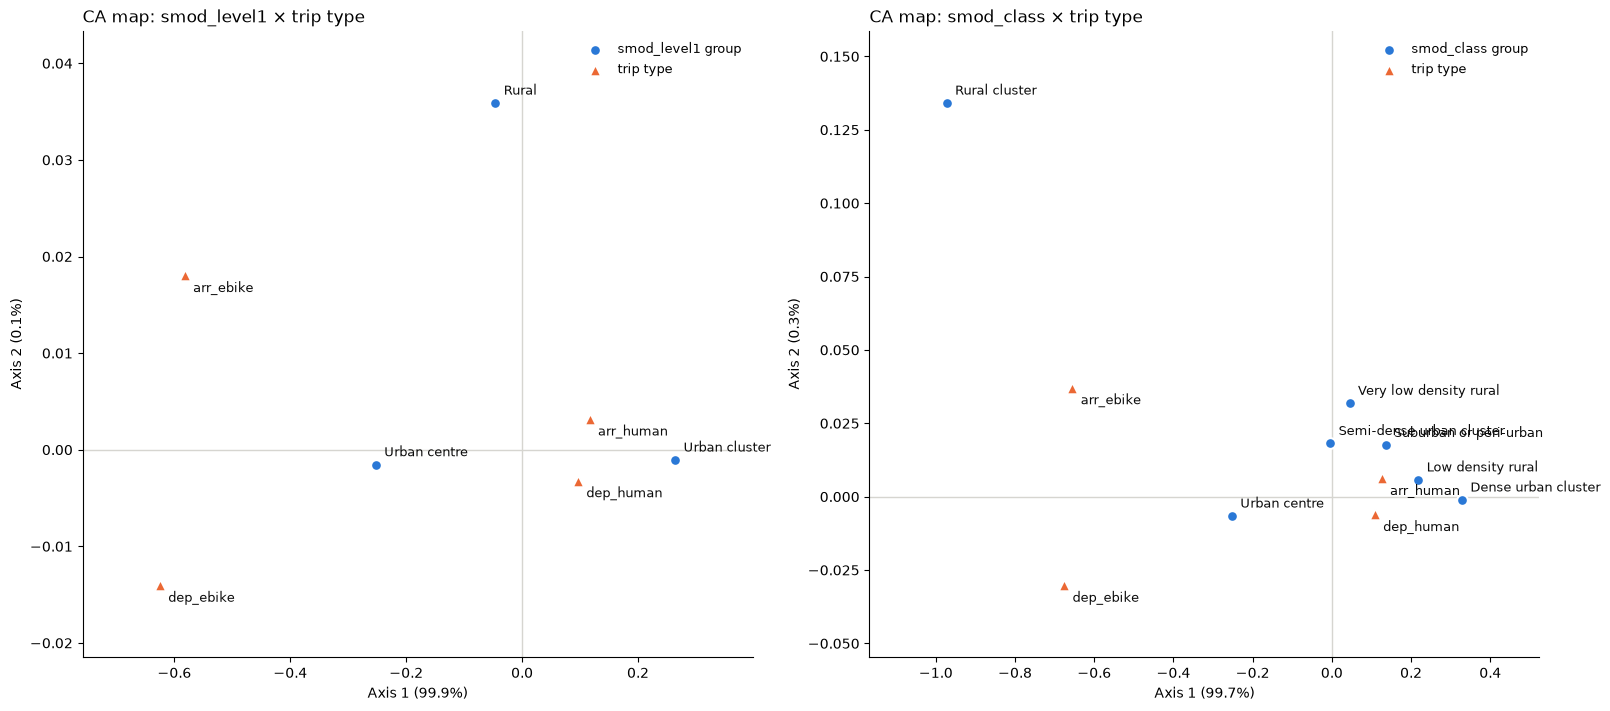

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")
for ax, (ca, table, group_col) in zip(axes, [(ca_level1, ca_table_level1, "smod_level1"),
                                              (ca_class, ca_table_class, "smod_class")]):
    rows = ca.row_coordinates(table)       # groups
    cols = ca.column_coordinates(table)    # trip types
    pct = np.asarray(ca.percentage_of_variance_)

    ax.scatter(rows[0], rows[1], s=60, marker="o", color="#2a78d6", edgecolor="white", linewidth=1.5,
               label=f"{group_col} group", zorder=3)
    for name, (x, y) in rows[[0, 1]].iterrows():
        ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=9, color="#0b0b0b")

    ax.scatter(cols[0], cols[1], s=70, marker="^", color="#eb6834", edgecolor="white", linewidth=1.5,
               label="trip type", zorder=3)
    for name, (x, y) in cols[[0, 1]].iterrows():
        ax.annotate(name, (x, y), xytext=(6, -12), textcoords="offset points", fontsize=9, color="#0b0b0b")

    ax.axhline(0, color="#d6d5d0", linewidth=1, zorder=0)
    ax.axvline(0, color="#d6d5d0", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(f"Axis 1 ({pct[0]:.1f}%)")
    ax.set_ylabel(f"Axis 2 ({pct[1]:.1f}%)")
    ax.margins(0.15)
    ax.legend(loc="best", frameon=False, fontsize=9)
    ax.set_title(f"CA map: {group_col} × trip type", loc="left")

plt.show()

### Step 35: `is_weekday`, `weekend_share_am` and `weekend_share_pm` columns

In [61]:
# 1. weekday flag on every status row (True Monday-Friday), the opposite of is_weekend (Step 9)
station_status["is_weekday"] = ~station_status["is_weekend"]
print(station_status["is_weekday"].value_counts())

# 2. share of each station's weekend rows in the morning (local hour 0-11) and in the afternoon/evening (12-23)
weekend_rows = station_status[station_status["is_weekend"]]
weekend_half = np.where(weekend_rows["hour"] < 12, "am", "pm")
weekend_counts = weekend_rows.groupby(["station_id", weekend_half]).size().unstack(fill_value=0)
weekend_share_am = weekend_counts["am"] / weekend_counts.sum(axis=1)

weekend_share_pm = weekend_counts["pm"] / weekend_counts.sum(axis=1)

stations["weekend_share_am"] = stations["id"].map(weekend_share_am)   # stations without weekend rows: NaN
stations["weekend_share_pm"] = stations["id"].map(weekend_share_pm)
print("Stations without weekend rows:", stations["weekend_share_am"].isna().sum())
stations[["weekend_share_am", "weekend_share_pm"]].describe().round(3)

is_weekday
True     2225413
False     700545
Name: count, dtype: int64
Stations without weekend rows: 36


,weekend_share_am,weekend_share_pm
count,2862.000,2862.000
mean,0.317,0.683
std,0.141,0.141
min,0.000,0.000
25%,0.229,0.608
50%,0.306,0.694
75%,0.392,0.771
max,1.000,1.000


### Step 36: FAMD and K-means with weekday am / pm shares (12-hour bins)

The pm shares and `human_share` are only displayed on the chart and not used for the analysis, because each one is 1 minus its am / e-bike partner.

The first 3 FAMD axes represent about 52% of the variance in the data.

Clustering worked better with 2 bins (am / pm) than with the other bin sizes: more variance explained and clusters that are easier to read.

In [62]:
min_weekday_rows_12h = 100   # same threshold as Steps 19 and 26

# share of each station's weekday rows in the morning (local hour 0-11) and afternoon/evening (12-23)
weekday_rows_12h = station_status[~station_status["is_weekend"]]
half_day = np.where(weekday_rows_12h["hour"] < 12, "wd_share_am", "wd_share_pm")
counts_12h = weekday_rows_12h.groupby(["station_id", half_day]).size().unstack(fill_value=0)
counts_12h = counts_12h[counts_12h.sum(axis=1) >= min_weekday_rows_12h]
wd_share_12h = counts_12h.div(counts_12h.sum(axis=1), axis=0)

print("Stations kept:", len(wd_share_12h))
wd_share_12h.describe().T.round(3)

Stations kept: 2243


,count,mean,std,min,25%,50%,75%,max
wd_share_am,2243.0,0.329,0.09,0.036,0.270,0.327,0.387,0.706
wd_share_pm,2243.0,0.671,0.09,0.294,0.613,0.673,0.730,0.964


In [63]:
# Step 28 FAMD with the 6-hour shares replaced by the 12-hour (am / pm) shares
# active numerical columns: shape the axes and the clusters
famd_numeric_12h = ["bike_racks", "mean_bikes", "log_rows_per_active_day", "weekend_share",
                    "wd_share_am",        # weekday rows in hours 0-11
                    "weekend_share_am",   # weekend rows in hours 0-11 (Step 35)
                    "ebike_share"]        # trip departures + arrivals by e-bike (Step 31)
# display-only numerical columns: the other half of each pair (= 1 - its partner),
# projected afterwards so they appear on the biplot without counting twice in the analysis
famd_numeric_display_12h = ["wd_share_pm", "weekend_share_pm", "human_share"]
famd_categorical_12h = ["smod_level1"]   # active
famd_supplementary_12h = ["country"]     # projected afterwards only

famd_input_12h = (
    station_features[["bike_racks", "mean_bikes", "log_rows_per_active_day", "weekend_share",
                      *famd_categorical_12h, *famd_supplementary_12h]]
    .join(wd_share_12h, how="inner")
    .join(stations.set_index("id")[["ebike_share", "human_share", "weekend_share_am", "weekend_share_pm"]])
)[famd_numeric_12h + famd_numeric_display_12h + famd_categorical_12h + famd_supplementary_12h]

# stations without any trip (no ebike_share) or without weekend rows (no weekend_share_am) are left out
n_with_shares = len(famd_input_12h)
print("Missing ebike_share:", famd_input_12h["ebike_share"].isna().sum(),
      "| missing weekend_share_am:", famd_input_12h["weekend_share_am"].isna().sum())
famd_input_12h = famd_input_12h.dropna(subset=["ebike_share", "weekend_share_am"])
print("Stations:", n_with_shares, "| left out:", n_with_shares - len(famd_input_12h), "| used:", len(famd_input_12h))

# number of dimensions: numerical columns + (categories - 1) per active categorical column
n_dims_12h = len(famd_numeric_12h) + sum(famd_input_12h[c].nunique() - 1 for c in famd_categorical_12h)
famd_12h = prince.FAMD(n_components=n_dims_12h, n_iter=5, random_state=42,
                       categorical_columns=famd_categorical_12h + famd_supplementary_12h)
famd_12h = famd_12h.fit(famd_input_12h, supplementary_columns=famd_supplementary_12h + famd_numeric_display_12h)
display(famd_12h.eigenvalues_summary)

# contribution (%) of each active variable to the first 4 axes
display((famd_12h.variable_contributions_.iloc[:, :4] * 100).round(1))

Missing ebike_share: 1 | missing weekend_share_am: 0
Stations: 2243 | left out: 1 | used: 2242


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,2.189,24.32%,24.32%
1,1.400,15.55%,39.87%
2,1.145,12.72%,52.59%
3,1.079,11.99%,64.58%
4,0.906,10.07%,74.65%
5,0.740,8.23%,82.87%
6,0.602,6.68%,89.56%
7,0.517,5.74%,95.30%
8,0.423,4.70%,100.00%


component,0,1,2,3
variable,,,,
bike_racks,25.3,6.6,0.0,1.5
mean_bikes,5.7,14.6,19.2,17.8
log_rows_per_active_day,20.9,11.9,2.0,0.2
weekend_share,6.8,23.2,12.5,0.5
wd_share_am,18.0,22.2,1.1,0.2
weekend_share_am,17.4,9.9,1.9,1.4
ebike_share,0.6,4.3,0.2,69.2
smod_level1,5.3,7.3,63.2,9.1


In [64]:
# same procedure as Steps 24, 26, 27 and 28: axes up to 90% of the variance -> K-means for k = 1..10
famd_coords_12h = famd_12h.row_coordinates(famd_input_12h)
cumulative_12h = np.asarray(famd_12h.cumulative_percentage_of_variance_) / 100
n_axes_12h = int(np.argmax(cumulative_12h >= 0.90)) + 1
cluster_input_famd_12h = famd_coords_12h.iloc[:, :n_axes_12h].to_numpy()
print(f"Axes used: {n_axes_12h} ({cumulative_12h[n_axes_12h - 1] * 100:.1f}% of variance)")

results_famd_12h = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_famd_12h)
    silhouette = silhouette_score(cluster_input_famd_12h, km.labels_) if k > 1 else np.nan   # undefined for k = 1
    results_famd_12h.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
kmeans_results_famd_12h = pd.DataFrame(results_famd_12h).set_index("k")

# elbow: same rule as Step 24
x = (kmeans_results_famd_12h.index - 1) / 9
y = (kmeans_results_famd_12h["inertia"] - kmeans_results_famd_12h["inertia"].min()) / (kmeans_results_famd_12h["inertia"].max() - kmeans_results_famd_12h["inertia"].min())
elbow_k_famd_12h = int(kmeans_results_famd_12h.index[np.argmax(np.abs(x + y - 1) / np.sqrt(2))])
print("Elbow at k =", elbow_k_famd_12h)

kmeans_results_famd_12h.round(3)

Axes used: 8 (95.3% of variance)
Elbow at k = 4


,inertia,silhouette
k,,
1,19229.443,NaN
2,15951.356,0.201
3,13795.702,0.221
4,12185.296,0.238
5,10933.815,0.219
6,9722.052,0.223
7,8998.938,0.208
8,8492.284,0.196
9,8085.112,0.205


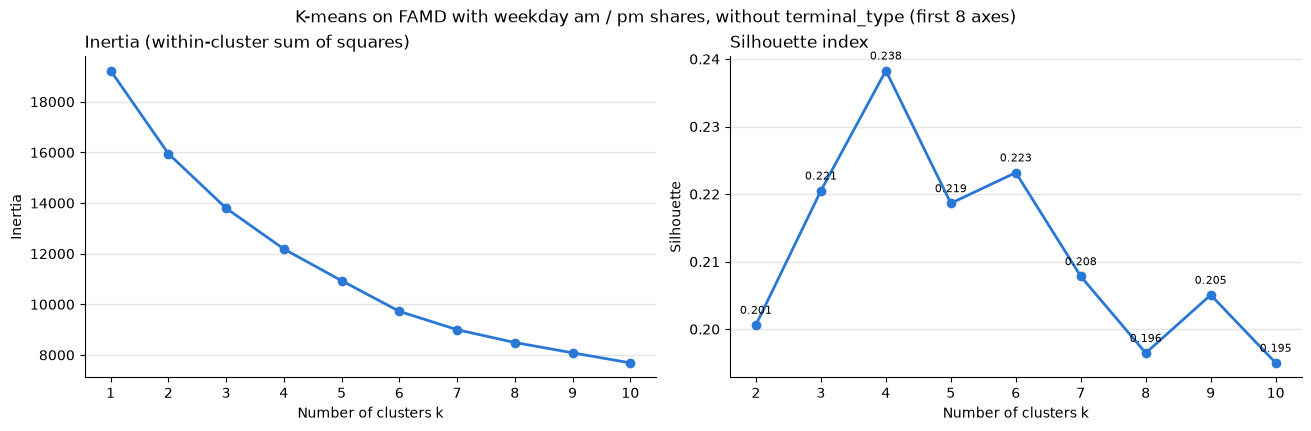

In [65]:
fig, (ax_in, ax_sil) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")

ax_in.plot(kmeans_results_famd_12h.index, kmeans_results_famd_12h["inertia"], color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
ax_in.set_title("Inertia (within-cluster sum of squares)", loc="left")
ax_in.set_ylabel("Inertia")

sil_famd_12h = kmeans_results_famd_12h["silhouette"].dropna()
ax_sil.plot(sil_famd_12h.index, sil_famd_12h.values, color="#2a78d6", lw=2, marker="o", ms=6, zorder=2)
for k, v in sil_famd_12h.items():
    ax_sil.annotate(f"{v:.3f}", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax_sil.set_title("Silhouette index", loc="left")
ax_sil.set_ylabel("Silhouette")

for ax in (ax_in, ax_sil):
    ax.set_xticks(list(kmeans_results_famd_12h.index) if ax is ax_in else list(sil_famd_12h.index))
    ax.set_xlabel("Number of clusters k")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"K-means on FAMD with weekday am / pm shares, without terminal_type (first {n_axes_12h} axes)")
plt.show()

### Step 37: K-means with 2, 3 and 4 clusters on the Step 36 FAMD, with biplots

k = 2 separates the stations into am and pm, and k = 3 separates the rural stations.

In [66]:
# K-means with k = 2, 3 and 4 on the Step 36 FAMD axes
cluster_labels_12h = pd.DataFrame(index=famd_input_12h.index)
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(cluster_input_famd_12h)
    cluster_labels_12h[f"k{k}"] = km.labels_
    print(f"k = {k}: silhouette = {silhouette_score(cluster_input_famd_12h, km.labels_):.3f}")

display(cluster_labels_12h.apply(lambda col: col.value_counts().sort_index()).fillna(0).astype(int).rename_axis("cluster"))

k = 2: silhouette = 0.201
k = 3: silhouette = 0.221
k = 4: silhouette = 0.238


,k2,k3,k4
cluster,,,
0,861,800,696
1,1381,1303,1171
2,0,139,236
3,0,0,139


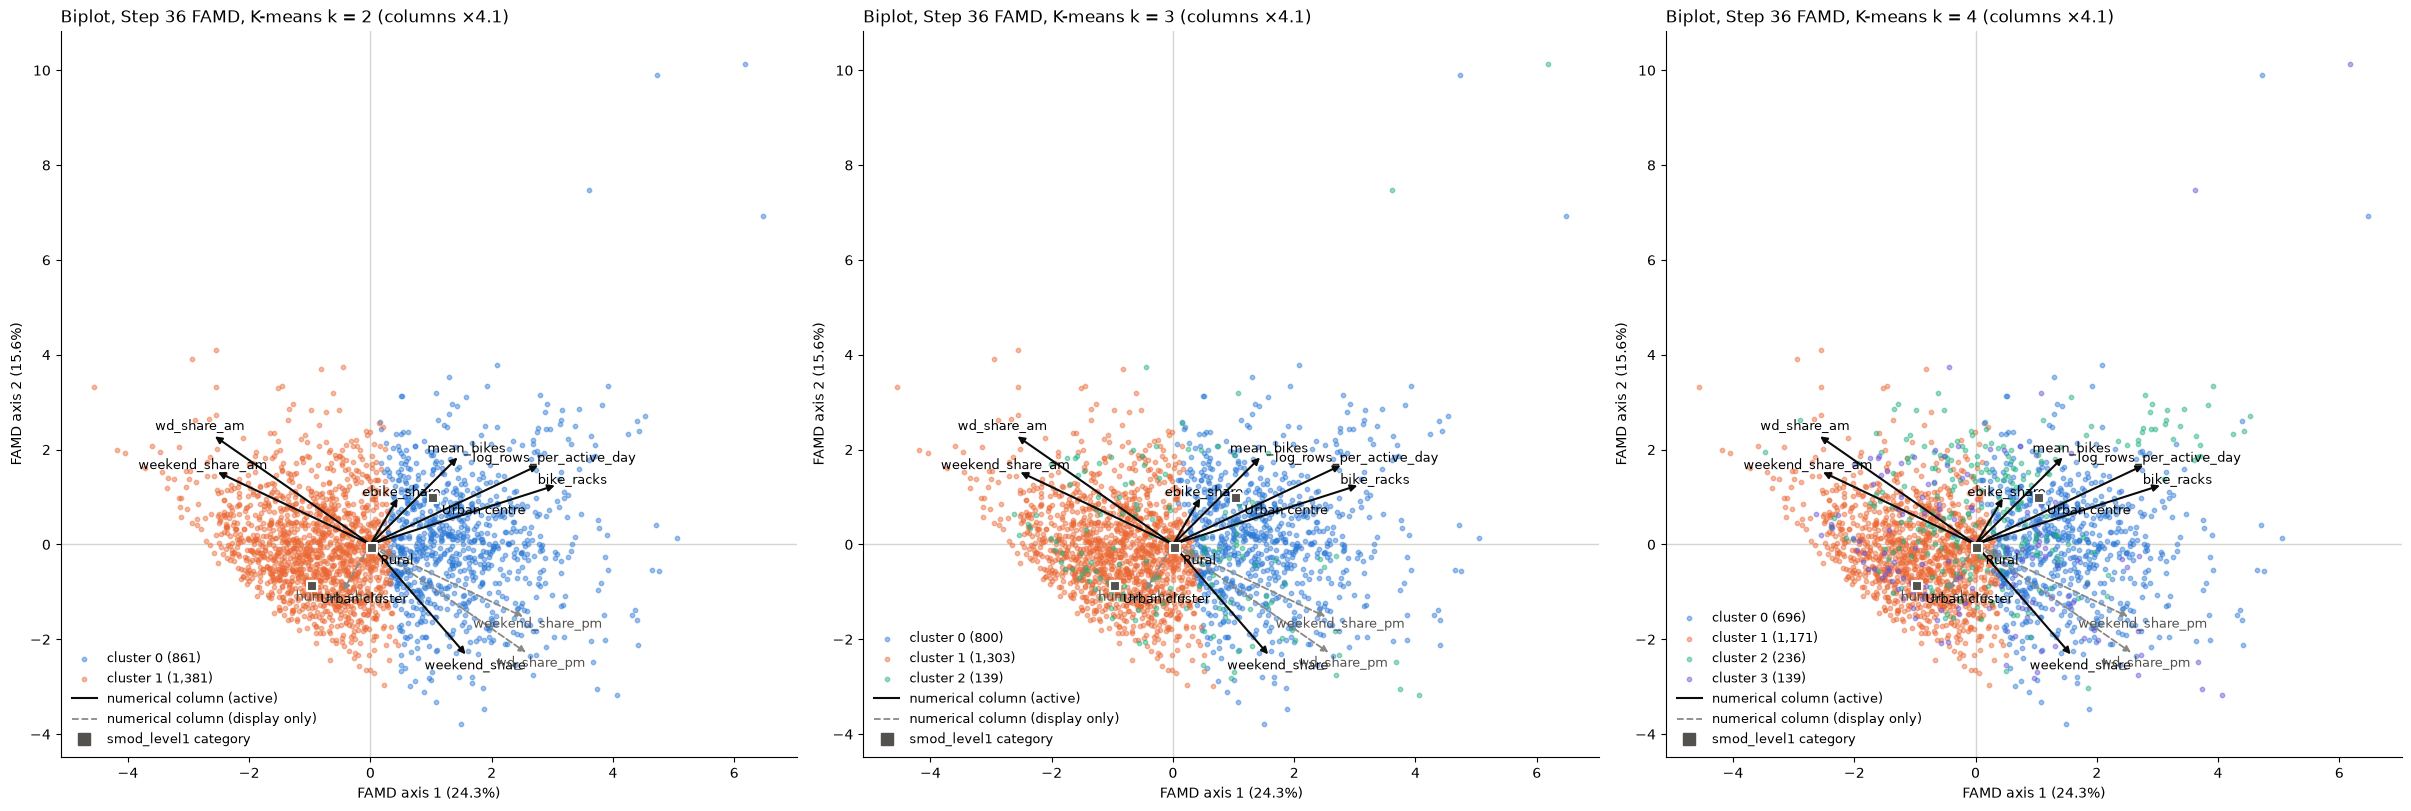

In [67]:
coords_12h = famd_12h.row_coordinates(famd_input_12h)            # stations on the FAMD axes
col_coords_12h = famd_12h.column_coordinates_                    # columns on the FAMD axes
pct_12h = np.asarray(famd_12h.percentage_of_variance_)

numeric_coords = col_coords_12h.loc[famd_numeric_12h, [0, 1]]    # active numerical columns -> solid arrows
display_coords = col_coords_12h.loc[famd_numeric_display_12h, [0, 1]]   # display-only columns -> dashed arrows
smod_coords = col_coords_12h.loc[[c for c in col_coords_12h.index if c.startswith("smod_level1_")], [0, 1]]  # categories -> points

# arrows and category points stretched by one factor so the longest reaches 90% of the stations' 99th-percentile score
col_scale = 0.9 * np.abs(coords_12h[[0, 1]]).quantile(0.99).max() / np.sqrt((pd.concat([numeric_coords, display_coords, smod_coords]) ** 2).sum(axis=1)).max()
cluster_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

fig, axes = plt.subplots(1, 3, figsize=(24, 8), layout="constrained")
for ax, k in zip(axes, [2, 3, 4]):
    labels_k = cluster_labels_12h[f"k{k}"]
    for c in sorted(labels_k.unique()):
        mask = labels_k == c
        ax.scatter(coords_12h.loc[mask, 0], coords_12h.loc[mask, 1], s=10, color=cluster_colors[c], alpha=0.45,
                   label=f"cluster {c} ({mask.sum():,})", zorder=1)

    for var, (x, y) in numeric_coords.iterrows():
        ax.annotate("", xy=(x * col_scale, y * col_scale), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color="#0b0b0b", lw=1.5), zorder=3)
        ax.text(x * col_scale * 1.08, y * col_scale * 1.08, var, fontsize=9, ha="center", va="center", zorder=4)
    for var, (x, y) in display_coords.iterrows():
        ax.annotate("", xy=(x * col_scale, y * col_scale), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color="#8a8984", lw=1.3, linestyle="--"), zorder=3)
        ax.text(x * col_scale * 1.08, y * col_scale * 1.08, var, fontsize=9, color="#52514e",
                ha="center", va="center", zorder=4)

    ax.scatter(smod_coords[0] * col_scale, smod_coords[1] * col_scale, marker="s", s=60, color="#52514e",
               edgecolor="white", linewidth=1.5, zorder=4)
    for name, (x, y) in smod_coords.iterrows():
        ax.annotate(name.replace("smod_level1_", ""), (x * col_scale, y * col_scale), xytext=(6, -12),
                    textcoords="offset points", fontsize=9, zorder=4)

    ax.axhline(0, color="#d6d5d0", linewidth=1, zorder=0)
    ax.axvline(0, color="#d6d5d0", linewidth=1, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(f"FAMD axis 1 ({pct_12h[0]:.1f}%)")
    ax.set_ylabel(f"FAMD axis 2 ({pct_12h[1]:.1f}%)")
    handles, _ = ax.get_legend_handles_labels()
    handles += [Line2D([], [], color="#0b0b0b", lw=1.5, label="numerical column (active)"),
                Line2D([], [], color="#8a8984", lw=1.3, linestyle="--", label="numerical column (display only)"),
                Line2D([], [], marker="s", linestyle="", color="#52514e", markersize=8, label="smod_level1 category")]
    ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=9)
    ax.set_title(f"Biplot, Step 36 FAMD, K-means k = {k} (columns ×{col_scale:.1f})", loc="left")

plt.show()

### Step 38: Rotatable 3D plot of the Step 36 FAMD (axes 1–3)

In [68]:
k = 3
labels_k = cluster_labels_12h[f"k{k}"]
coords_3d = famd_12h.row_coordinates(famd_input_12h)[[0, 1, 2]]    # stations on FAMD axes 1-3 (Step 36)
col_coords_3d = famd_12h.column_coordinates_[[0, 1, 2]]
pct_3d = np.asarray(famd_12h.percentage_of_variance_)[:3]

active_3d = col_coords_3d.loc[famd_numeric_12h]              # active numerical columns -> solid lines
display_3d = col_coords_3d.loc[famd_numeric_display_12h]     # display-only columns -> dashed lines
# column lines stretched by one factor so the longest reaches 90% of the stations' 99th-percentile score
scale_3d = 0.9 * np.abs(coords_3d).quantile(0.99).max() / np.sqrt((pd.concat([active_3d, display_3d]) ** 2).sum(axis=1)).max()
cluster_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

fig = go.Figure()

# stations, one trace per cluster (click a legend entry to hide / show it)
station_info_3d = famd_input_12h[["smod_level1", "country"]]
for c in sorted(labels_k.unique()):
    mask = labels_k == c
    fig.add_trace(go.Scatter3d(
        x=coords_3d.loc[mask, 0], y=coords_3d.loc[mask, 1], z=coords_3d.loc[mask, 2],
        mode="markers", name=f"cluster {c} ({mask.sum():,})",
        marker=dict(size=2.5, color=cluster_colors[c], opacity=0.5),
        customdata=np.column_stack([coords_3d.index[mask], station_info_3d.loc[mask].to_numpy()]),
        hovertemplate="station %{customdata[0]}<br>%{customdata[1]}, %{customdata[2]}<extra>cluster " + str(c) + "</extra>",
    ))

# columns: a line from the origin with the column name at its end
for vectors, color, dash, group in [(active_3d, "#0b0b0b", "solid", "active columns"),
                                    (display_3d, "#8a8984", "dash", "display-only columns")]:
    for i, (var, (x, y, z)) in enumerate(vectors.iterrows()):
        fig.add_trace(go.Scatter3d(
            x=[0, x * scale_3d], y=[0, y * scale_3d], z=[0, z * scale_3d],
            mode="lines+text", text=["", var], textposition="top center",
            line=dict(color=color, width=4, dash=dash), textfont=dict(color=color, size=11),
            name=group, legendgroup=group, showlegend=(i == 0), hoverinfo="skip",
        ))

fig.update_layout(
    title=f"Stations on FAMD axes 1-3 (Step 36), K-means k = {k} (columns ×{scale_3d:.1f})",
    scene=dict(xaxis_title=f"Axis 1 ({pct_3d[0]:.1f}%)",
               yaxis_title=f"Axis 2 ({pct_3d[1]:.1f}%)",
               zaxis_title=f"Axis 3 ({pct_3d[2]:.1f}%)"),
    width=1000, height=800, legend=dict(itemsizing="constant"),
)
fig.show()

### Step 39: Rotatable 3D plot of the Step 36 FAMD with k = 2

In [69]:
k = 2
labels_k = cluster_labels_12h[f"k{k}"]
coords_3d = famd_12h.row_coordinates(famd_input_12h)[[0, 1, 2]]    # stations on FAMD axes 1-3 (Step 36)
col_coords_3d = famd_12h.column_coordinates_[[0, 1, 2]]
pct_3d = np.asarray(famd_12h.percentage_of_variance_)[:3]

active_3d = col_coords_3d.loc[famd_numeric_12h]              # active numerical columns -> solid lines
display_3d = col_coords_3d.loc[famd_numeric_display_12h]     # display-only columns -> dashed lines
# column lines stretched by one factor so the longest reaches 90% of the stations' 99th-percentile score
scale_3d = 0.9 * np.abs(coords_3d).quantile(0.99).max() / np.sqrt((pd.concat([active_3d, display_3d]) ** 2).sum(axis=1)).max()
cluster_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

fig = go.Figure()

# stations, one trace per cluster (click a legend entry to hide / show it)
station_info_3d = famd_input_12h[["smod_level1", "country"]]
for c in sorted(labels_k.unique()):
    mask = labels_k == c
    fig.add_trace(go.Scatter3d(
        x=coords_3d.loc[mask, 0], y=coords_3d.loc[mask, 1], z=coords_3d.loc[mask, 2],
        mode="markers", name=f"cluster {c} ({mask.sum():,})",
        marker=dict(size=2.5, color=cluster_colors[c], opacity=0.5),
        customdata=np.column_stack([coords_3d.index[mask], station_info_3d.loc[mask].to_numpy()]),
        hovertemplate="station %{customdata[0]}<br>%{customdata[1]}, %{customdata[2]}<extra>cluster " + str(c) + "</extra>",
    ))

# columns: a line from the origin with the column name at its end
for vectors, color, dash, group in [(active_3d, "#0b0b0b", "solid", "active columns"),
                                    (display_3d, "#8a8984", "dash", "display-only columns")]:
    for i, (var, (x, y, z)) in enumerate(vectors.iterrows()):
        fig.add_trace(go.Scatter3d(
            x=[0, x * scale_3d], y=[0, y * scale_3d], z=[0, z * scale_3d],
            mode="lines+text", text=["", var], textposition="top center",
            line=dict(color=color, width=4, dash=dash), textfont=dict(color=color, size=11),
            name=group, legendgroup=group, showlegend=(i == 0), hoverinfo="skip",
        ))

fig.update_layout(
    title=f"Stations on FAMD axes 1-3 (Step 36), K-means k = {k} (columns ×{scale_3d:.1f})",
    scene=dict(xaxis_title=f"Axis 1 ({pct_3d[0]:.1f}%)",
               yaxis_title=f"Axis 2 ({pct_3d[1]:.1f}%)",
               zaxis_title=f"Axis 3 ({pct_3d[2]:.1f}%)"),
    width=1000, height=800, legend=dict(itemsizing="constant"),
)
fig.show()

### Step 40: Other clustering algorithms for k = 2 and 3

In [70]:
# other clustering algorithms on the same input as Step 37 (Step 36 FAMD axes), for k = 2 and 3
algorithms = {
    "K-means": lambda k: KMeans(n_clusters=k, n_init=20, random_state=42),
    "Agglomerative (Ward)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
    "Gaussian mixture": lambda k: GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42),
    "Spectral (nearest neighbours)": lambda k: SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                                                   n_neighbors=15, random_state=42),
}

algo_labels = pd.DataFrame(index=famd_input_12h.index)
algo_results = []
for k in [2, 3]:
    for name, make in algorithms.items():
        labels = make(k).fit_predict(cluster_input_famd_12h)
        algo_labels[f"{name} k{k}"] = labels
        algo_results.append({
            "k": k,
            "algorithm": name,
            "silhouette": silhouette_score(cluster_input_famd_12h, labels),            # higher is better
            "Davies-Bouldin": davies_bouldin_score(cluster_input_famd_12h, labels),    # lower is better
            "Calinski-Harabasz": calinski_harabasz_score(cluster_input_famd_12h, labels),  # higher is better
            "ARI with K-means": adjusted_rand_score(cluster_labels_12h[f"k{k}"], labels),  # 1 = same clusters as K-means
            "cluster sizes": sorted(np.bincount(labels).tolist(), reverse=True),
        })
algo_results = pd.DataFrame(algo_results).set_index(["k", "algorithm"])
algo_results.round(3)

silhouette  Davies-Bouldin  \
k algorithm                                                   
2 K-means                             0.201           1.946   
  Agglomerative (Ward)                0.190           2.381   
  Gaussian mixture                    0.404           1.303   
  Spectral (nearest neighbours)       0.404           1.303   
3 K-means                             0.221           1.579   
  Agglomerative (Ward)                0.206           1.802   
  Gaussian mixture                    0.210           1.986   
  Spectral (nearest neighbours)       0.202           1.757   

                                 Calinski-Harabasz  ARI with K-means  \
k algorithm                                                            
2 K-means                                  460.332             1.000   
  Agglomerative (Ward)                     330.103             0.374   
  Gaussian mixture                         311.070             0.005   
  Spectral (nearest neighbours)            311.070             0.005   
3 K-means                                  440.940             1.000   
  Agglomerative (Ward)                     372.129             0.505   
  Gaussian mixture                         279.175             0.180   
  Spectral (nearest neighbours)            372.745             0.212   

                                    cluster sizes  
k algorithm                                        
2 K-means                             [1381, 861]  
  Agglomerative (Ward)                [1349, 893]  
  Gaussian mixture                    [2103, 139]  
  Spectral (nearest neighbours)       [2103, 139]  
3 K-means                        [1303, 800, 139]  
  Agglomerative (Ward)           [1349, 753, 140]  
  Gaussian mixture               [1713, 390, 139]  
  Spectral (nearest neighbours)  [1144, 959, 139]

In [71]:
# share of rural stations and mean weekday morning share per cluster, for each algorithm
for col in algo_labels.columns:
    labels = algo_labels[col]
    summary = pd.DataFrame({
        "stations": labels.value_counts().sort_index(),
        "rural share": (famd_input_12h["smod_level1"] == "Rural").groupby(labels).mean().round(2),
        "wd_share_am": famd_input_12h["wd_share_am"].groupby(labels).mean().round(3),
        "ebike_share": famd_input_12h["ebike_share"].groupby(labels).mean().round(3),
        "bike_racks": famd_input_12h["bike_racks"].groupby(labels).mean().round(1),
    })
    print(f"\n{col}")
    display(summary.rename_axis("cluster"))


K-means k2


,stations,rural share,wd_share_am,ebike_share,bike_racks
cluster,,,,,
0,861,0.07,0.276,0.167,12.0
1,1381,0.06,0.363,0.098,3.1



Agglomerative (Ward) k2


,stations,rural share,wd_share_am,ebike_share,bike_racks
cluster,,,,,
0,893,0.16,0.303,0.289,10.9
1,1349,0.00,0.346,0.016,3.6



Gaussian mixture k2


,stations,rural share,wd_share_am,ebike_share,bike_racks
cluster,,,,,
0,2103,0.0,0.329,0.117,6.6
1,139,1.0,0.341,0.242,5.9


... (6 outputs left out)


Gaussian mixture k3


,stations,rural share,wd_share_am,ebike_share,bike_racks
cluster,,,,,
0,390,0.0,0.331,0.624,7.3
1,1713,0.0,0.328,0.001,6.4
2,139,1.0,0.341,0.242,5.9



Spectral (nearest neighbours) k3


,stations,rural share,wd_share_am,ebike_share,bike_racks
cluster,,,,,
0,1144,0.0,0.333,0.103,5.2
1,959,0.0,0.323,0.133,8.3
2,139,1.0,0.341,0.242,5.9


### Step 41: 3D plots of the Step 40 clustering algorithms

The clusters are consistent across algorithms: a clear split between rural and urban stations, with the urban stations further divided into am and pm stations.

In [72]:
# one rotatable 3D scatter per algorithm and k (Step 40 labels), stations on FAMD axes 1-3 of Step 36
coords_3d = famd_12h.row_coordinates(famd_input_12h)[[0, 1, 2]]
pct_3d = np.asarray(famd_12h.percentage_of_variance_)[:3]
cluster_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
algo_names = list(algorithms)
k_values = [2, 3]

fig = make_subplots(
    rows=len(k_values), cols=len(algo_names),
    specs=[[{"type": "scene"}] * len(algo_names) for _ in k_values],
    subplot_titles=[f"{name}, k = {k}" for k in k_values for name in algo_names],
    horizontal_spacing=0.01, vertical_spacing=0.05,
)
for r, k in enumerate(k_values, start=1):
    for c, name in enumerate(algo_names, start=1):
        labels = algo_labels[f"{name} k{k}"]
        for cl in sorted(labels.unique()):
            mask = labels == cl
            fig.add_trace(go.Scatter3d(
                x=coords_3d.loc[mask, 0], y=coords_3d.loc[mask, 1], z=coords_3d.loc[mask, 2],
                mode="markers", marker=dict(size=2, color=cluster_colors[cl], opacity=0.5),
                name=f"cluster {cl}", legendgroup=f"cluster {cl}", showlegend=bool((r == 1 and c == 1) or (k == 3 and c == 1 and cl == 2)),
                hovertemplate=f"{name}, k = {k}<br>cluster {cl}<br>station %{{customdata}}<extra></extra>",
                customdata=coords_3d.index[mask],
            ), row=r, col=c)

# same axis titles on every 3D panel
axis_titles = dict(xaxis_title=f"Axis 1 ({pct_3d[0]:.0f}%)", yaxis_title=f"Axis 2 ({pct_3d[1]:.0f}%)",
                   zaxis_title=f"Axis 3 ({pct_3d[2]:.0f}%)")
fig.update_scenes(**axis_titles)
fig.update_layout(title="Stations on FAMD axes 1-3 (Step 36), coloured by cluster for each algorithm (Step 40)",
                  width=1800, height=950, legend=dict(itemsizing="constant"))
fig.show()